# Racetrack Ring Resonator — Cascaded Hybrid Simulation

Built with raw meep/meow instead of BEEF's solver classes. Same device as
`ring_resonator_hybrid.ipynb`, but the coupler section (bus + near straight
+ both near bends) is split into a 3-section cascade — **[left near-bend
section] -> [straight coupled-pair body] -> [right near-bend section]** —
mirroring `directional_coupler_hybrid.ipynb`'s FDTD(x2)+EME(x1) pattern,
instead of one monolithic FDTD domain.

```
                          L_FAR (not drawn — analytic neff phase only)
                    .------------------------.
                   /                          \
              far bend                     far bend      <- standalone
                  |                              |           bend FDTD,
              L_SIDE (analytic neff)          L_SIDE          reused x2
                  |                              |
             near-left bend                near-right bend  <- THIS notebook's
                  |                              |             LEFT-SECTION FDTD
    "bus in" ----------------- L_C -------------------- "bus out"
                     (near straight, coupled to bus)
```

**Why a cascade instead of a monolithic domain:** unlike a standard
directional coupler (both arms bend symmetrically), here the **bus never
bends** — only the ring arm bends, via the near-left/near-right arcs. The
natural 3-way cut is at `x = +-L_C/2`, where bus+ring sit parallel at the
full coupling gap, decomposable into 2 supermodes (even/odd):

- **Left section** (bus straight-through + near-left bend + a shortened ring
  stub): 2 FDTD excitations (bus-in, ring-in), each giving one column of a
  2x2 transfer matrix `M_left` (rows = the 2 supermodes at the body
  interface).
- **Right section**: the exact x-mirror of the left. By reciprocity, its own
  transfer matrix is simply `M_left.transpose()` — **never separately
  simulated**, exactly like `directional_coupler_hybrid`'s
  `M_out_through`/`M_out_cross` reuse.
- **Body** (straight coupled pair, length `BODY_LENGTH = L_C - 2*IFACE_BUFFER`):
  a pure mode-solve (num_modes=2, even/odd) giving a diagonal
  phase-propagation matrix `P_body`, same idea as
  `EMESolver.solve_section_length_sweep()`'s `S_ii(L)=exp(2j*pi*neff_i/wl*L)`.

Full coupler-section transfer matrix: `S_coupler = M_left.T @ P_body @
M_left` (2x2, per wavelength) — `t=S_coupler[bus,bus]`,
`k1=S_coupler[ring,bus]`, `k2=S_coupler[bus,ring]`, `t_ring=S_coupler[ring,ring]`,
feeding into the **same, unchanged** closed-form all-pass resonator assembly:

```
phi = 2*pi*neff(lambda)*L_outer/lambda
b_corrected = b(lambda) * (per-bend reference-plane phase correction)
P = b_corrected**2 * exp(1j*phi)
E_thru = t + k1*k2*P / (1 - t_ring*P)
T = |E_thru|**2
```

⚠ **Corrected 2026-08-03 — the line above used to claim this was "a
stronger internal self-check than the monolithic version's
independently-normalized `|k1|~=|k2|`". That is backwards.** Since
`P_body` is diagonal, `S_coupler` is symmetric **by construction** — `k1`
and `k2` are the same matrix element read from either side, so
`k1==k2` to floating-point precision is an IDENTITY, not a measurement.
It cannot fail no matter what the FDTD returns, so it is not evidence and
is not part of this example's validation basis. The monolithic route's
check is the one that can fail — and does, at `1.3e-04` with `0.0068*pi`
of arg drift, unexplained after six tested mechanisms
(`resolved/ring_resonator_validation.md`). The real, independent
coefficient-level check for THIS route is power conservation,
`|t|^2+|k1|^2`, printed below — nothing in the network algebra forces an
FDTD-measured `M_left` to conserve power. Measured post-M1 in 3-D (job
11658568): `0.999640 .. 0.999926`, deviation `3.6e-04`.

**Note:** this notebook defaults to `RING_TEST_MODE=1` (reduced resolution,
2-D, few wavelengths) — a smoke test of the whole pipeline, not a physical
result. Set `RING_TEST_MODE=0` before launching Jupyter for the full-res
3-D production run (takes hours).

In [1]:
import os

import numpy as np
import matplotlib

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.path as mpath

import meep as mp
import meow as mw

from beef import extrude_polygons
from beef.cache import CacheMissError, load_result, lookup, save_run
from beef.geometry.base import polygons_to_prisms
from beef.materials import SOI_220
from beef.materials.stack import resolved_material_config
from beef.results import SMatrix
from beef.solvers.fdtd import (
    check_source_coverage, monitor_freq_grid, source_fwidth,
)
from beef.spectral import interp_complex

_HERE = os.getcwd()
output_dir = os.path.abspath(os.path.join(_HERE, "..", "..", "..", "..", "example_output", "ring_resonator", "ring_resonator_hybrid_cascaded"))
# A gap-3 resolution sweep (RING_FDTD_RES set, see FDTD_RESOLUTION below) writes
# into its own subfolder. Without this every array task would overwrite the same
# ring_data.npz and the production result with it -- which is exactly how the
# 2026-08-03 smoke run destroyed the 11634900_1 arrays. The guard is the env var,
# not the value, so a deliberate res-40 sweep task still stays out of the way.
_res_sweep = os.environ.get("RING_FDTD_RES")
if _res_sweep:
    output_dir = os.path.join(output_dir, "res_sweep", f"res_{float(_res_sweep):g}")
# RING_THREE_D likewise gets its own subfolder, and for the same reason: a 2-D
# run's ring_data.npz is not the production result and must never land on top of
# it. Same "guard is the env var, not the value" rule as above.
_three_d_env = os.environ.get("RING_THREE_D")
if _three_d_env is not None:
    output_dir = os.path.join(output_dir,
                              "three_d" if bool(int(_three_d_env)) else "two_d")
os.makedirs(output_dir, exist_ok=True)
# Per-simulation geometry previews live here; the top level keeps the
# whole-device assembly diagram and the results plots. One folder per kind of
# thing that gets simulated: 2 FDTD domains (left section, standalone bend) and
# 2 mode-solve cross-sections (coupled pair for the body, bare strip for the
# outer arms).
sections_dir = os.path.join(output_dir, "sections")
os.makedirs(sections_dir, exist_ok=True)

# Persistent on-disk simulation cache (see beef/cache/) — same shared
# example_sim_cache/ directory every other example (including
# ring_resonator_hybrid.py) points at.
save_dir = os.path.abspath(os.path.join(_HERE, "..", "..", "..", "..", "example_sim_cache"))

Using MPI version 4.1, 1 processes


In [2]:
# ---------------------------------------------------------------------------
# 0. Test-mode knob — see ring_resonator_hybrid.py's identical knob.
# ---------------------------------------------------------------------------
TEST_MODE = bool(int(os.environ.get("RING_TEST_MODE", "0")))

In [3]:
# ---------------------------------------------------------------------------
# 1. Global simulation / geometry parameters (220 nm SOI, C-band) — identical
#    to ring_resonator_hybrid.py.
# ---------------------------------------------------------------------------
MATERIAL_STACK = SOI_220
WAVEGUIDE_WIDTH = 0.45     # um, single-mode strip width
GAP = 0.25                 # um, bus<->ring edge-to-edge coupling gap
R = 5.0                    # um, bend radius (centerline)
L_C = 2.0                  # um, near (coupling) straight length — the coupling-strength knob
L_SIDE = 10.0                # um, each vertical side straight (analytic neff only)
L_FAR = L_C                 # um, far straight (analytic neff only)

# ring_resonator_validation.md gap 3 / the coupler's P3 knob-split precedent.
# ONE shared RESOLUTION used to drive both the meep FDTD and the meow/MPB mode
# solve. The coupler split its own for a reason -- "shared RESOLUTION was how a
# 7% error hid for months (dc_validation.md item 11)" -- and this device had the
# same defect, measured 2026-08-01 (job 11616610):
#
#   res    n_eff@1.55   d(round-trip phase)
#    40     2.311706      --   (shipped)
#   100     2.339523    +1.58 rad = 25.1% OF A FULL FSR
#
# The mode solve is what sets resonance position (phi = 2*pi*n_eff*L_outer/lambda),
# it converges at 100, and it is CHEAP -- the whole six-resolution sweep ran in
# 4:34. So it goes to 100. The FDTD side has never been measured at any
# resolution and 3-D FDTD cost scales roughly as res^4, so it stays at 40 rather
# than paying ~39x for an unmeasured claim. Splitting is what makes those two
# independent statements expressible at all.
# pts/um -- meep. Overridable via RING_FDTD_RES so gap 3's missing half (FDTD-side
# resolution convergence, check 3) can be swept as a SLURM array without editing the
# script. The cache fingerprint already includes `resolution`, so each value gets its
# own entry and no run can be served another's result. Outputs are redirected per
# resolution below for the same reason -- an unguarded sweep would have every task
# overwrite one ring_data.npz.
FDTD_RESOLUTION = float(os.environ.get(
    "RING_FDTD_RES", 20.0 if TEST_MODE else 40.0))
MODE_RESOLUTION = 20.0 if TEST_MODE else 100.0   # pts/um -- meow/MPB; gap 3 converged
# 2-D/3-D is now its OWN knob, split out of TEST_MODE 2026-08-03.
#
# Why: validation check 4 (ring_resonator_fdtd.py) can only afford the full
# device in 2-D -- 3-D is 167 h at res 40, past the wall limit -- so the
# comparison it exists for needs a 2-D run of THIS script to compare against.
# RING_TEST_MODE=1 cannot be that partner: it changes FIVE things at once
# (FDTD res -> 20, MODE_RESOLUTION -> 20, 2-D, N_WL_FDTD -> 21, N_WL_SOLVE -> 5,
# and N_WL_DENSE -> 2001, which is known grid-limited for Q). Any disagreement
# against it would be uninterpretable -- there would be no way to tell a
# decomposition error from four confounded knobs.
#
# RING_THREE_D=0 drops to 2-D and changes NOTHING else, so a full-device-vs-
# hybrid comparison isolates the one variable it is about. Unset keeps the old
# behaviour exactly (TEST_MODE decides), so no existing invocation moves.
THREE_D = (not TEST_MODE) if _three_d_env is None else bool(int(_three_d_env))
WL_MIN, WL_MAX = 1.50, 1.60                    # um, C-band
N_WL_FDTD = 21 if TEST_MODE else 101           # FDTD DFT points
N_WL_SOLVE = 5 if TEST_MODE else 13            # mode-solve points — each a real MPB solve
N_WL_DENSE = 2001 if TEST_MODE else 20001     # dense interpolated grid, to resolve resonance dips.
# Raised from 501/2001 on 2026-08-03 because Q was GRID-LIMITED, not physical: at 2001
# points the 1.50-1.60 um span steps 0.05 nm, and every reported FWHM came out an exact
# multiple of it (0.15/0.20/0.25/0.30 = 3/4/5/6 steps), so Q was set by this knob rather
# than by either resolution. 20001 points = 0.005 nm, ~30 samples across the narrowest
# FWHM seen so far. Pure post-processing on interpolated coefficients -- costs no FDTD and
# is in no cache fingerprint (the FDTD grid is `wavelengths`, N_WL_FDTD, which is separate).
# CONVERGENCE VERIFIED, not assumed: rebuilding the dense assembly from the same cached
# coefficients at 2001/5001/10001/20001/40001/80001 points gives first-dip FWHM
# 0.1500/0.1400/0.1100/0.1050/0.1050/0.1050 nm -- flat from 20001 on. The old 2001-point
# value under-reported Q by ~43% (10006 vs 14294). Do not lower this to "save time": it is
# an interpolation, and the whole reported Q spectrum moves with it.
DPML = 0.5
SIM_HEIGHT = 1.5            # um, inner z-span when THREE_D
DECAY_TOL = 1e-11
SOURCE_BANDWIDTH_FACTOR = 2.0   # see ring_resonator_hybrid.py's identical constant
SOURCE_MARGIN = 0.0
MONITOR_MARGIN = 0.25
S_MON = 0.5                 # um, ring-port reference plane offset above each near bend's arc end
STUB_LEN = 1.5               # um, standalone far-bend stub length (unchanged; NOT used by the
                              # left/near-bend section anymore — see LEFT_STUB_TOP below)
PORT_APERTURE = 3.0           # um, mode-decomposition window width at bus/ring access ports

_cell_sz = (SIM_HEIGHT + 2 * DPML) if THREE_D else 0.0
_mon_sz = SIM_HEIGHT if THREE_D else 0.0
_wg_height = MATERIAL_STACK.wg_height if THREE_D else None

# Perimeter = 2 horizontal straights (L_C near + L_FAR far) + 2 vertical
# straights (2*L_SIDE) + 4 quarter bends (= one full circle, 2*pi*R).
PERIMETER = L_C + L_FAR + 2 * L_SIDE + 2 * np.pi * R
NG_GUESS = 4.3   # typical group index for a 450x220 Si strip, C-band — just for the printed FSR estimate
FSR_GUESS = (1.55 ** 2) / (NG_GUESS * PERIMETER)
print(f"Racetrack perimeter: {PERIMETER:.2f} um  ->  predicted FSR ~ {FSR_GUESS*1000:.2f} nm "
      f"(~{(WL_MAX-WL_MIN)/FSR_GUESS:.1f} resonances across {WL_MIN}-{WL_MAX} um)")
if TEST_MODE:
    print("RING_TEST_MODE=1: reduced res/2-D/few wavelengths — smoke test only, not a physical result.")

Racetrack perimeter: 55.42 um  ->  predicted FSR ~ 10.08 nm (~9.9 resonances across 1.5-1.6 um)


In [4]:
# ---------------------------------------------------------------------------
# 2. Polygon helpers — identical to ring_resonator_hybrid.py.
# ---------------------------------------------------------------------------
def arc_polygon(cx, cy, r_inner, r_outer, theta0_deg, theta1_deg, n_pts=64):
    """Quarter-annulus wedge vertex list — same construction as
    beef/geometry/bend.py's _arc_polygon."""
    t0, t1 = np.radians(theta0_deg), np.radians(theta1_deg)
    thetas = np.linspace(t0, t1, n_pts)
    outer = [(cx + r_outer * np.cos(t), cy + r_outer * np.sin(t)) for t in thetas]
    inner = [(cx + r_inner * np.cos(t), cy + r_inner * np.sin(t)) for t in reversed(thetas)]
    return outer + inner

def rect_poly(x0, y0, x1, y1):
    return [(x0, y0), (x1, y0), (x1, y1), (x0, y1)]

In [5]:
# ---------------------------------------------------------------------------
# 3. Coupler-section cascade geometry: LEFT section (bus straight-through +
#    near-left bend + shortened ring stub) is the only piece simulated in
#    FDTD; the BODY is a pure mode-solve cross-section (section 8); the
#    RIGHT section is the exact x-mirror of the left, reused algebraically
#    (see module docstring), never separately built or simulated.
#
#    Bus at y=0; near straight at y_ring = WAVEGUIDE_WIDTH + GAP. The
#    near-left bend arc (cx=-L_C/2, cy=Y_RING+R, theta 180->270) starts at
#    (-STUB_X, Y_RING+R) [stub bottom] and ends at (-L_C/2, Y_RING) [near-
#    straight's left end] — confirmed directly from arc_polygon()'s own
#    parametrization. Substituting x -> -x maps that arc onto
#    arc_polygon(+L_C/2, ..., theta 270->360) — the (unbuilt, reused-by-
#    mirror) near-right bend — confirming the two are exact x-mirrors and
#    L_C/2 is the correct interface cut.
# ---------------------------------------------------------------------------
W = WAVEGUIDE_WIDTH
Y_RING = W + GAP
STUB_X = L_C / 2 + R                    # x of both vertical stub columns
Y_BELOW = 2.0                            # inner clearance below the bus
INNER_X_HALF = STUB_X + Y_BELOW          # bus extends this far past the stub columns (inner, no PML)

N_MODES = 2   # even + odd supermodes of the coupled pair

MESH_WIDTH = 4.0     # um, bare single-strip mode-solve lateral mesh span (section 8) — also sizes
MESH_HEIGHT = 2.0    # um, mode-solve mesh z-span                            the coupled-pair cross-section/interface monitor below
_MODE_MARGIN = MESH_WIDTH / 2 - W / 2             # per-strip lateral oxide clearance, reused for the coupled pair
BODY_Y_CENTER = Y_RING / 2
BODY_MESH_WIDTH = Y_RING + W + 2 * _MODE_MARGIN   # coupled-pair cross-section lateral mesh span

IFACE_BUFFER = 1.0   # um, straight buffer past each near bend before the interface mode-decomposition
                     # monitor — comparable to the standalone bend's own STUB_LEN-MONITOR_MARGIN
                     # buffer (section 4), letting the ring waveguide's near-field relax into a clean
                     # guided mode after the bend before supermode decomposition.
IFACE_X = -L_C / 2 + IFACE_BUFFER                  # domain edge, IFACE_BUFFER past the near-left bend's endpoint
IFACE_Y_CENTER = BODY_Y_CENTER
IFACE_WIDTH = BODY_MESH_WIDTH                      # match the coupled-pair mode solve's own lateral span

# THE interface plane — the one place it is defined. The supermode monitor is
# placed here and the body's modelled length is derived FROM here, so the two
# cannot disagree about where the body starts.
#
# They did disagree until 2026-08-03: the monitor sat at IFACE_X - MONITOR_MARGIN
# while BODY_LENGTH was L_C - 2*IFACE_BUFFER, i.e. the length subtracted the
# plane the DOMAIN was drawn to rather than the plane actually MEASURED at. The
# body then propagated 2.00 um across a 2.50 um gap and the model's round trip
# came out 0.5 um shorter than PERIMETER. Compare
# directional_coupler_hybrid.py, which subtracts 2*BODY_STUB and whose interface
# monitor really is exactly BODY_STUB past its bend end -- there the subtracted
# number IS the monitor offset, which is why its length audit holds.
#
# NOTE the offset kept here is MONITOR_MARGIN *inward* from IFACE_X. That is not
# the library convention: FDTDSolver puts a measure plane exactly on the section
# boundary (`mea_x = L` in _section_layout()), insetting only the excite/norm
# side. Moving to that convention is a separate change -- it alters what the FDTD
# measures, so it needs the 3-D runs redone AND a fingerprint/schema bump first
# (the derived monitor position is not in _sim_params(), so the cache would
# silently serve the old measurement). Deriving the length is correct either way.
IFACE_PLANE_L = IFACE_X - MONITOR_MARGIN           # supermode decomposition plane, left section
IFACE_PLANE_R = -IFACE_PLANE_L                     # right section is the exact x-mirror
BODY_LENGTH = IFACE_PLANE_R - IFACE_PLANE_L        # straight length the supermode phase must carry
assert BODY_LENGTH > 0, "IFACE_BUFFER too large for L_C — shorten IFACE_BUFFER or lengthen L_C"

LEFT_RING_Y   = Y_RING + R + S_MON              # canonical ring-port plane, both directions (== the
                                                 # monolithic version's ring_r_mon convention) —
                                                 # required so M_right=M_left.T is a valid reuse
LEFT_STUB_TOP = LEFT_RING_Y + MONITOR_MARGIN    # source plane, MONITOR_MARGIN above the port plane
                                                 # (same offset pattern the bus port already uses)

LEFT_X_MIN, LEFT_X_MAX = -INNER_X_HALF - DPML, IFACE_X + DPML
LEFT_Y_MIN, LEFT_Y_MAX = -Y_BELOW - DPML, LEFT_STUB_TOP + DPML
LEFT_SX = LEFT_X_MAX - LEFT_X_MIN
LEFT_SY = LEFT_Y_MAX - LEFT_Y_MIN
LEFT_X_CENTER = (LEFT_X_MAX + LEFT_X_MIN) / 2.0
LEFT_Y_CENTER = (LEFT_Y_MAX + LEFT_Y_MIN) / 2.0

def build_left_polys():
    """Left section: bus (through x-PML on both ends — outer left port, and
    the closing PML just past the body interface) + near-left bend
    (unchanged from the monolithic design) + a short near-straight sliver
    (bend endpoint -> IFACE_BUFFER past it, through the same closing PML,
    keeping the ring waveguide physically present at the interface monitor
    plane) + a shortened ring stub ending in y-PML at LEFT_RING_Y."""
    return [
        rect_poly(-INNER_X_HALF - DPML, -W / 2, IFACE_X + DPML, W / 2),                 # bus, PML both ends
        rect_poly(-L_C / 2, Y_RING - W / 2, IFACE_X + DPML, Y_RING + W / 2),             # near-straight sliver, bend->interface, through PML
        arc_polygon(-L_C / 2, Y_RING + R, R - W / 2, R + W / 2, 180, 270),               # near-left bend, unchanged
        rect_poly(-STUB_X - W / 2, Y_RING + R, -STUB_X + W / 2, LEFT_STUB_TOP + DPML),   # shortened left stub, through y-PML
    ]


def _left_polys_relative():
    """build_left_polys(), translated so LEFT_X_CENTER sits at x=0 — i.e. the
    domain shape actually simulated (make_sim() passes LEFT_X_CENTER as
    geometry_center, so meep only ever sees positions relative to it).

    Every x-coordinate in build_left_polys() is (L_C-independent constant)
    - L_C/2, and LEFT_X_CENTER is itself -L_C/2 + a constant, so subtracting
    it cancels L_C exactly regardless of L_C's value — this fingerprint is
    the same for L_C=4.0 and L_C=8.0 (or any other value), matching the fact
    that run_left_fdtd() simulates the same relative geometry either way.
    Used only for the cache key; build_left_polys() (absolute coordinates)
    is still what's actually built into the meep simulation."""
    return [[(x - LEFT_X_CENTER, y) for x, y in poly] for poly in build_left_polys()]

In [6]:
# ---------------------------------------------------------------------------
# 4. Standalone 90-degree bend geometry — identical to ring_resonator_hybrid.py.
# ---------------------------------------------------------------------------
BEND_X_MIN, BEND_X_MAX = -STUB_LEN - DPML, R + Y_BELOW + DPML
BEND_Y_MIN, BEND_Y_MAX = -Y_BELOW - DPML, R + STUB_LEN + DPML
BEND_SX = BEND_X_MAX - BEND_X_MIN
BEND_SY = BEND_Y_MAX - BEND_Y_MIN
BEND_X_CENTER = (BEND_X_MAX + BEND_X_MIN) / 2.0
BEND_Y_CENTER = (BEND_Y_MAX + BEND_Y_MIN) / 2.0

def build_bend_polys():
    return [
        rect_poly(-STUB_LEN - DPML, -W / 2, 0.0, W / 2),               # input stub, through x-PML
        arc_polygon(0.0, R, R - W / 2, R + W / 2, -90, 0),              # the bend itself
        rect_poly(R - W / 2, R, R + W / 2, R + STUB_LEN + DPML),        # output stub, through y-PML
    ]

BEND_D_IN = STUB_LEN - MONITOR_MARGIN
BEND_D_OUT = STUB_LEN - MONITOR_MARGIN

In [7]:
# ---------------------------------------------------------------------------
# The straight guide the standalone-bend FDTD carries INSIDE its own measured
# coefficient: BEND_D_IN before the arc and BEND_D_OUT after it, per bend -- and
# b is squared, because there are two far bends. phi_bend_correction strips that
# PHASE out of b so b_corrected refers to the arc endpoints, and L_OUTER then
# supplies the full physical straights. Net straight phase = L_OUTER.
#
# Equivalent formulation, verified 2026-08-03 to 1.2e-13 in T and to identical
# dip wavelengths: never touch b, and use L_OUTER - BEND_STRAIGHT_TOTAL as the
# analytic length instead. That is the DirectionalCoupler's approach
# (`body_lengths = coupling_lengths - 2*BODY_STUB`). The two agree exactly because
# both strip and re-add with the same neff. Keeping the strip because it is
# MANDATORY whenever the difference below would go negative, and because
# b_corrected ("the arc alone") stays meaningful across ring geometries.
#
# THE GUARD. The DC has one (`assert body_lengths[0] >= 0`); this script did not
# until 2026-08-03. The equivalent analytic length must not go negative: if the
# bend's own stubs cover more straight than the device physically has between its
# arcs, the model attributes straight to the bends that does not exist -- and it
# would do so SILENTLY. Headroom here is only 2.0 um, and in terms of the knob that
# sets it, only 0.5 um: BEND_STRAIGHT_TOTAL = 4*(STUB_LEN - MONITOR_MARGIN), so
# STUB_LEN = 2.0 is exactly the boundary and anything above it trips this assert
# (verified by exercising this block against broken configs, 2026-08-03). A smaller
# ring trips it without touching the bend at all -- L_SIDE=1.0, L_FAR=2.0 at the
# shipped STUB_LEN already fails.
#
# Note this uses the SHIPPED L_outer expression. Whether that expression is itself
# plane-consistent is a separate question -- see the round-trip ledger, which
# reports it.
# ---------------------------------------------------------------------------
L_OUTER = 2 * (L_SIDE - S_MON) + L_FAR
BEND_STRAIGHT_TOTAL = 2 * (BEND_D_IN + BEND_D_OUT)          # 2 far bends
BEND_STRAIGHT_HEADROOM = L_OUTER - BEND_STRAIGHT_TOTAL
# Which of the two equivalent bend-straight accountings this run uses. Defined
# here so the ledger and the assembly figure can label themselves correctly;
# the P assembly re-derives the same condition where it applies it.
_BEND_LABEL = ("b_corrected (FDTD, planes stripped)" if BEND_STRAIGHT_HEADROOM < 0
               else "b as measured (DC-style: analytic length shortened instead)")
# How much straight each far bend's FDTD domain keeps on EACH side of its arc.
# Zero under the phase-strip form (it is removed from b and handed back to
# L_outer); BEND_D_IN/OUT under the DC-style form (it stays inside b).
_BEND_EAT = 0.0 if BEND_STRAIGHT_HEADROOM < 0 else BEND_D_IN
_BEND_SPAN_NOTE = "" if BEND_STRAIGHT_HEADROOM < 0 else " (less bend stubs)"
_BEND_ARC_NOTE = " arc" if BEND_STRAIGHT_HEADROOM < 0 else " arc + its 2x1.25 stubs"
assert BEND_STRAIGHT_HEADROOM >= 0, (
    f"the far bends' own straight stubs ({BEND_STRAIGHT_TOTAL:.2f} um total) exceed "
    f"the physical straight path between the arcs (L_OUTER = {L_OUTER:.2f} um), so the "
    f"DC-style equivalent analytic length would be negative. Reduce STUB_LEN or "
    f"MONITOR_MARGIN, or lengthen L_SIDE / L_FAR."
)

In [8]:
# ---------------------------------------------------------------------------
# 5. Raw-meep simulation helpers — identical to ring_resonator_hybrid.py.
# ---------------------------------------------------------------------------
# ---------------------------------------------------------------------------
# M1 FIX, 2026-08-03 — the FDTD half now tracks the band.
#
# Until today both media were built with `si_medium(wl_center)` / a SCALAR, so
# the whole 1.50-1.60 um sweep ran on one index frozen at band centre while the
# meow/EME half re-evaluated its SampledMaterials at every wavelength. The two
# engines were simulating different silicon: n_Si off by +0.004338 at 1.50 um
# and -0.003913 at 1.60 um, which is +1.42% / -1.20% of an FSR in round-trip
# phase.
#
# The library fixed this on 2026-08-01 inside `FDTDSolver._media()`, so every
# example that goes through the solver inherited it with no edit. These ring
# scripts are the ONLY non-library callers of si_medium/sio2_medium in the repo
# -- they hand-roll mp.Simulation and never construct an FDTDSolver, so they
# could not inherit a solver fix. This function is `FDTDSolver._media()`
# replicated, deliberately line-for-line, rather than a second opinion about
# what "dispersive" means.
#
# NOTE the reparameterisation matters and is not optional: a naive dispersive
# meep Medium LOSES 0.0496 in n_eff at res 40, because meep subpixel-averages
# only the instantaneous eps and meep's Sellmeier form puts eps_inf = 1, giving
# no Si/SiO2 contrast for smoothing to act on. `si_medium(dispersive=True)`
# routes through `meep_medium_reparam()`, which puts the contrast back in
# eps_inf. See MaterialStack.si_medium()'s docstring for the measurement.
#
# RING_FDTD_DISPERSIVE overrides for an A/B; unset inherits the stack (True).
_disp_env = os.environ.get("RING_FDTD_DISPERSIVE")
FDTD_DISPERSIVE = None if _disp_env is None else bool(int(_disp_env))

def _media(wavelengths):
    """(si_medium, sio2_medium) for this run's band -- FDTDSolver._media()."""
    dispersive = MATERIAL_STACK.resolve_dispersive(FDTD_DISPERSIVE)
    wl = (np.asarray(wavelengths, dtype=float) if dispersive
          else float(np.mean(wavelengths)))
    return (MATERIAL_STACK.si_medium(wl, dispersive=dispersive),
            MATERIAL_STACK.sio2_medium(wl, dispersive=dispersive))

def make_sim(polys, wavelengths, cell_size, geometry_center):
    """`wavelengths` is the run's whole BAND, not a centre wavelength -- see
    _media() above for why that distinction is the entire M1 fix."""
    si, sio2 = _media(wavelengths)
    prisms = polygons_to_prisms(polys, si, wg_height=_wg_height)
    return mp.Simulation(
        resolution=FDTD_RESOLUTION,
        cell_size=mp.Vector3(cell_size[0], cell_size[1], _cell_sz),
        geometry_center=mp.Vector3(geometry_center[0], geometry_center[1], 0),
        boundary_layers=[mp.PML(DPML)],
        geometry=prisms,
        default_material=sio2,
    )

def add_x_monitor(sim, mon_freqs, x, yc, width=PORT_APERTURE):
    """See ring_resonator_hybrid.py's identical helper for why this takes an
    explicit frequency list from monitor_freq_grid() rather than meep's
    (fcen, df, nfreq) triple (dc_validation.md items 1 and 10)."""
    return sim.add_mode_monitor(
        mon_freqs,
        mp.FluxRegion(center=mp.Vector3(x, yc), size=mp.Vector3(0, width, _mon_sz)),
    )

def add_y_monitor(sim, mon_freqs, y, xc, width=PORT_APERTURE):
    """See add_x_monitor() — same contract, y-normal plane."""
    return sim.add_mode_monitor(
        mon_freqs,
        mp.FluxRegion(center=mp.Vector3(xc, y), size=mp.Vector3(width, 0, _mon_sz)),
    )

def get_coeffs(sim, mon, band=1, forward=True):
    """See ring_resonator_hybrid.py's identical helper for the full
    forward/backward-index explanation."""
    coeff = sim.get_eigenmode_coefficients(mon, [band], eig_parity=mp.NO_PARITY)
    return coeff.alpha[0, :, 0 if forward else 1]

def _json_polys(polys):
    """Polygon vertex lists -> plain JSON-safe floats, for a cache config's
    geometry_polygons (mirrors beef.cache.config's own float-rounding)."""
    return [[[round(float(x), 9), round(float(y), 9)] for x, y in poly] for poly in polys]

def _sim_params(wavelengths):
    """Every module-level constant that affects the physical result of
    run_left_fdtd()/run_bend_fdtd() — changing any of these must change the
    cache key. IFACE_BUFFER isn't listed separately: it's already baked into
    build_left_polys()'s vertex coordinates, which geometry_polygons
    fingerprints directly.

    L_C is NOT here: it only shifts both build_left_polys() and make_sim()'s
    geometry_center by the same -L_C/2, so the simulated domain (and
    run_bend_fdtd's, which never depended on L_C to begin with) is bit-
    identical across L_C values. run_left_fdtd's own geometry_polygons
    fingerprint is taken relative to LEFT_X_CENTER (see _left_polys_relative())
    precisely so this stays true of the cache key too — putting L_C here
    would re-invalidate the cache on every L_C edit for no physical reason.

    The two `resolved_*` entries strand this script's pre-fix cache entries —
    see ring_resonator_hybrid.py's identical helper for why deriving them from
    already-hashed `wavelengths` is still the point."""
    mon_freqs, _ = monitor_freq_grid(wavelengths)
    return {
        "resolved_monitor_freqs": [round(float(f), 9) for f in mon_freqs],
        "resolved_source_fwidth": round(
            float(source_fwidth(wavelengths, SOURCE_BANDWIDTH_FACTOR)), 9),
        "waveguide_width": WAVEGUIDE_WIDTH,
        "gap": GAP,
        "R": R,
        "resolution": FDTD_RESOLUTION,
        "three_d": THREE_D,
        "sim_height": SIM_HEIGHT,
        "dpml": DPML,
        "decay_tol": DECAY_TOL,
        "source_margin": SOURCE_MARGIN,
        "monitor_margin": MONITOR_MARGIN,
        "port_aperture": PORT_APERTURE,
        "y_below": Y_BELOW,
        "stub_len": STUB_LEN,
        "s_mon": S_MON,
        "material_stack": {"wg_height": MATERIAL_STACK.wg_height, "sz": MATERIAL_STACK.sz},
        # M3 (ring_resonator_validation.md): geometry alone is NOT a material
        # fingerprint. Without the resolved indices, neither the 2026-07-28
        # Sellmeier change nor the 2026-08-01 dispersion-default flip moves this
        # key, so a stale entry keeps matching and is served with the old
        # physics -- the same failure the resolved_* spectral fields above exist
        # to stop, on the material axis. The third argument is the RESOLVED
        # value (M4), not the stack's flag.
        #
        # M1 FIXED 2026-08-03: it used to be a hardcoded `False`, because the
        # FDTD half really did simulate frozen media -- si_medium(wl_center)
        # with a SCALAR. It now passes the band (see _media()), so this
        # resolves to True and the key turns over correctly, exactly as the M4
        # note predicted it would need to.
        **resolved_material_config(MATERIAL_STACK, np.asarray(wavelengths),
                                  MATERIAL_STACK.resolve_dispersive(FDTD_DISPERSIVE)),
    }

def get_norm_calibrated(sim, mon, forward=True):
    """See ring_resonator_hybrid.py's identical helper for the full
    flux-calibration explanation (needed for the ring-excited -y launch)."""
    coeff = get_coeffs(sim, mon, forward=forward)
    flux = np.abs(np.asarray(mp.get_fluxes(mon)))
    return np.sqrt(flux) * np.exp(1j * np.angle(coeff))

In [9]:
# ---------------------------------------------------------------------------
# 6. Left-section FDTD — one column of the 2x2 coupler transfer matrix per
#    excitation (bus-in or ring-in), read off at the body interface in the
#    2-supermode (even/odd) basis.
# ---------------------------------------------------------------------------
def run_left_fdtd(excite, wavelengths, save_dir=None, cache_only=False):
    """excite: "bus" or "ring". Returns complex ndarray
    [len(wavelengths), N_MODES] — one column of M_left (rows = the 2
    supermodes at the body interface x=IFACE_X, band 1 assumed higher-neff
    ["even"]/band 2 lower-neff ["odd"], matching solve_body_supermodes()'s
    explicit descending-neff sort — meep's own band-index order is trusted
    directly, same assumption every FDTDSolver call in this repo already
    makes, no re-sort).

    save_dir/cache_only: identical semantics to
    ring_resonator_hybrid.py's run_coupler_fdtd()."""
    config = None
    if save_dir:
        config = {
            "solver_type": "ring_resonator_hybrid_cascaded.run_left_fdtd",
            "method": excite,
            "geometry_class": "RingResonatorLeftSection",
            "geometry_polygons": {"2,0": _json_polys(_left_polys_relative())},
            "wavelengths": [round(float(w), 9) for w in wavelengths],
            "n_modes": N_MODES,
            **_sim_params(wavelengths),
        }
        hit = lookup(save_dir, config)
        if hit is not None:
            print(f"  [cache] run_left_fdtd({excite!r}) hit -> {hit}")
            return load_result(hit)
    if cache_only:
        raise CacheMissError(
            f"run_left_fdtd({excite!r}): cache_only=True but no cached run "
            f"found for this config (save_dir={save_dir!r}). Run once with "
            f"cache_only=False to populate the cache."
        )

    wl_center = float(np.mean(wavelengths))
    fcen = 1.0 / wl_center
    fwidth = source_fwidth(wavelengths, SOURCE_BANDWIDTH_FACTOR)
    mon_freqs, wl_order = monitor_freq_grid(wavelengths)
    check_source_coverage(fcen, fwidth, wavelengths)

    polys = build_left_polys()
    sim = make_sim(polys, wavelengths, (LEFT_SX, LEFT_SY), (LEFT_X_CENTER, LEFT_Y_CENTER))

    if excite == "bus":
        src_x = -INNER_X_HALF + SOURCE_MARGIN
        sim.sources = [mp.EigenModeSource(
            mp.GaussianSource(fcen, fwidth=fwidth),
            center=mp.Vector3(src_x, 0.0), size=mp.Vector3(0, PORT_APERTURE, _mon_sz),
            eig_band=1, eig_kpoint=mp.Vector3(1, 0, 0), eig_match_freq=True,
        )]
        norm_mon = add_x_monitor(sim, mon_freqs, -INNER_X_HALF + MONITOR_MARGIN, 0.0)
    elif excite == "ring":
        src_y = LEFT_STUB_TOP - SOURCE_MARGIN
        sim.sources = [mp.EigenModeSource(
            mp.GaussianSource(fcen, fwidth=fwidth),
            center=mp.Vector3(-STUB_X, src_y), size=mp.Vector3(PORT_APERTURE, 0, _mon_sz),
            eig_band=1, eig_kpoint=mp.Vector3(0, -1, 0), eig_match_freq=True,
        )]
        norm_mon = add_y_monitor(sim, mon_freqs, LEFT_RING_Y, -STUB_X)
    else:
        raise ValueError(f"unknown excite={excite!r}")

    iface_mon = add_x_monitor(sim, mon_freqs, IFACE_PLANE_L, IFACE_Y_CENTER, width=IFACE_WIDTH)

    sim.run(until_after_sources=mp.stop_when_dft_decayed(tol=DECAY_TOL))

    if excite == "bus":
        a_norm = get_coeffs(sim, norm_mon, forward=True)
    else:
        # launched -y — flux-calibrated normalization, see get_norm_calibrated()
        a_norm = get_norm_calibrated(sim, norm_mon, forward=False)

    coeff = sim.get_eigenmode_coefficients(iface_mon, list(range(1, N_MODES + 1)), eig_parity=mp.NO_PARITY)
    # alpha and a_norm are both in monitor order, so take the ratio there and
    # reorder once onto `wavelengths` along axis 0 — see ring_resonator_hybrid.py.
    col = (coeff.alpha[:, :, 0] / a_norm[np.newaxis, :]).T[wl_order]   # [n_wl, N_MODES], forward (+x, into the body)
    sim.reset_meep()

    if save_dir:
        folder = save_run(save_dir, config, col)
        print(f"  [cache] run_left_fdtd({excite!r}) saved -> {folder}")
    return col

In [10]:
# ---------------------------------------------------------------------------
# 7. Standalone 90-degree bend FDTD — identical to ring_resonator_hybrid.py.
# ---------------------------------------------------------------------------
def run_bend_fdtd(wavelengths, save_dir=None, cache_only=False):
    config = None
    if save_dir:
        config = {
            "solver_type": "ring_resonator_hybrid_cascaded.run_bend_fdtd",
            "method": "run_bend_fdtd",
            "geometry_class": "RingResonatorBend",
            "geometry_polygons": {"2,0": _json_polys(build_bend_polys())},
            "wavelengths": [round(float(w), 9) for w in wavelengths],
            **_sim_params(wavelengths),
        }
        hit = lookup(save_dir, config)
        if hit is not None:
            print(f"  [cache] run_bend_fdtd hit -> {hit}")
            return load_result(hit)
    if cache_only:
        raise CacheMissError(
            f"run_bend_fdtd(): cache_only=True but no cached run found for "
            f"this config (save_dir={save_dir!r}). Run once with "
            f"cache_only=False to populate the cache."
        )

    wl_center = float(np.mean(wavelengths))
    fcen = 1.0 / wl_center
    fwidth = source_fwidth(wavelengths, SOURCE_BANDWIDTH_FACTOR)
    mon_freqs, wl_order = monitor_freq_grid(wavelengths)
    check_source_coverage(fcen, fwidth, wavelengths)

    polys = build_bend_polys()
    sim = make_sim(polys, wavelengths, (BEND_SX, BEND_SY), (BEND_X_CENTER, BEND_Y_CENTER))

    src_x = -STUB_LEN + SOURCE_MARGIN
    sim.sources = [mp.EigenModeSource(
        mp.GaussianSource(fcen, fwidth=fwidth),
        center=mp.Vector3(src_x, 0.0), size=mp.Vector3(0, PORT_APERTURE, _mon_sz),
        eig_band=1, eig_kpoint=mp.Vector3(1, 0, 0), eig_match_freq=True,
    )]
    norm_mon = add_x_monitor(sim, mon_freqs, -STUB_LEN + MONITOR_MARGIN, 0.0)
    out_mon = add_y_monitor(sim, mon_freqs, R + STUB_LEN - MONITOR_MARGIN, R)

    sim.run(until_after_sources=mp.stop_when_dft_decayed(tol=DECAY_TOL))

    # Ratio in monitor order, reordered once onto `wavelengths`.
    a_norm = get_coeffs(sim, norm_mon, forward=True)
    b_raw = (get_coeffs(sim, out_mon, forward=True) / a_norm)[wl_order]
    sim.reset_meep()

    if save_dir:
        folder = save_run(save_dir, config, b_raw)
        print(f"  [cache] run_bend_fdtd saved -> {folder}")
    return b_raw

In [11]:
# ---------------------------------------------------------------------------
# 8. Mode solves — bare single-mode strip neff(lambda) (unchanged, for the
#    side/far straight phases) AND the coupled-pair (body) supermodes (new).
# ---------------------------------------------------------------------------
def build_strip_cross_section(length=1.0):
    """Bare single-strip mode-solve cross-section, as (wg_polys, oxide_polys).

    The single source for both solve_neff()'s cache fingerprint and the
    sections/ preview plot, so the picture cannot drift from what is solved.
    """
    return ([rect_poly(0.0, -W / 2, length, W / 2)],
            [rect_poly(0.0, -MESH_WIDTH / 2, length, MESH_WIDTH / 2)])

def build_body_cross_section(length=1.0):
    """Coupled bus+ring mode-solve cross-section, as (wg_polys, oxide_polys).
    Single source for solve_body_supermodes()'s fingerprint and its preview."""
    return ([rect_poly(0.0, -W / 2, length, W / 2),
             rect_poly(0.0, Y_RING - W / 2, length, Y_RING + W / 2)],
            [rect_poly(0.0, BODY_Y_CENTER - BODY_MESH_WIDTH / 2,
                       length, BODY_Y_CENTER + BODY_MESH_WIDTH / 2)])

def solve_neff(wl, save_dir=None, cache_only=False):
    config = None
    if save_dir:
        _wg, _ox = build_strip_cross_section()
        config = {
            "solver_type": "ring_resonator_hybrid_cascaded.solve_neff",
            "method": "solve_neff",
            "geometry_class": "BareStrip",
            "geometry_polygons": {
                "2,0": _json_polys(_wg),
                "1,0": _json_polys(_ox),
            },
            "waveguide_width": WAVEGUIDE_WIDTH,
            "resolution": MODE_RESOLUTION,
            "mesh_width": MESH_WIDTH,
            "mesh_height": MESH_HEIGHT,
            "material_stack": {"wg_height": MATERIAL_STACK.wg_height, "sz": MATERIAL_STACK.sz},
            # M3/M4: same reasoning as _sim_params(). dispersive=True here and
            # NOT False as on the FDTD side, because this is the meow half --
            # it builds media from MATERIAL_STACK.extrusion_rules (SampledMaterial,
            # re-evaluated per wavelength), so it genuinely IS exact-per-lambda.
            # That asymmetry is M2, and recording it truthfully in the key is
            # the point: the two halves currently simulate DIFFERENT media, and
            # a fingerprint that hid that would be the bug, not the fix.
            **resolved_material_config(MATERIAL_STACK, np.asarray([float(wl)]), True),
            "wavelength": round(float(wl), 9),
        }
        hit = lookup(save_dir, config)
        if hit is not None:
            return load_result(hit)
    if cache_only:
        raise CacheMissError(
            f"solve_neff(wl={wl!r}): cache_only=True but no cached run found "
            f"for this config (save_dir={save_dir!r}). Run once with "
            f"cache_only=False to populate the cache."
        )

    length = 1.0
    wg_poly = rect_poly(0.0, -W / 2, length, W / 2)
    ox_poly = rect_poly(0.0, -MESH_WIDTH / 2, length, MESH_WIDTH / 2)
    gds_polys = {(2, 0): [wg_poly], (1, 0): [ox_poly]}

    structs = extrude_polygons(gds_polys, MATERIAL_STACK.extrusion_rules)
    mesh = mw.Mesh2D(
        x=np.linspace(-MESH_WIDTH / 2, MESH_WIDTH / 2, int(MODE_RESOLUTION * MESH_WIDTH) + 1),
        y=np.linspace(-MESH_HEIGHT / 2, MESH_HEIGHT / 2, int(MODE_RESOLUTION * MESH_HEIGHT) + 1),
    )
    cells = mw.create_cells(structures=structs, mesh=mesh, Ls=[length])
    env = mw.Environment(wl=float(wl), T=25.0)
    cs = mw.CrossSection.from_cell(cell=cells[0], env=env)

    from meow import compute_modes_meep
    modes = compute_modes_meep(cs, num_modes=1)
    neff = float(np.real(modes[0].neff))

    if save_dir:
        save_run(save_dir, config, neff)
    return neff

def solve_body_supermodes(wl, save_dir=None, cache_only=False):
    """Even/odd supermode neff of the coupled bus+ring cross-section at one
    wavelength (num_modes=2, analogue of solve_neff() above). Returns
    (neff_even, neff_odd), sorted by np.real(neff) descending — must match
    run_left_fdtd()'s band-index (1=even,2=odd) convention."""
    length = 1.0
    (wg_bus, wg_ring), (ox_poly,) = build_body_cross_section(length)

    config = None
    if save_dir:
        config = {
            "solver_type": "ring_resonator_hybrid_cascaded.solve_body_supermodes",
            "method": "solve_body_supermodes",
            "geometry_class": "CoupledPairCrossSection",
            "geometry_polygons": {"2,0": _json_polys([wg_bus, wg_ring]), "1,0": _json_polys([ox_poly])},
            "waveguide_width": WAVEGUIDE_WIDTH, "gap": GAP, "y_ring": Y_RING,
            "resolution": MODE_RESOLUTION, "body_mesh_width": BODY_MESH_WIDTH, "mesh_height": MESH_HEIGHT,
            "num_modes": 2,
            "material_stack": {"wg_height": MATERIAL_STACK.wg_height, "sz": MATERIAL_STACK.sz},
            # M3/M4: same reasoning as _sim_params(). dispersive=True here and
            # NOT False as on the FDTD side, because this is the meow half --
            # it builds media from MATERIAL_STACK.extrusion_rules (SampledMaterial,
            # re-evaluated per wavelength), so it genuinely IS exact-per-lambda.
            # That asymmetry is M2, and recording it truthfully in the key is
            # the point: the two halves currently simulate DIFFERENT media, and
            # a fingerprint that hid that would be the bug, not the fix.
            **resolved_material_config(MATERIAL_STACK, np.asarray([float(wl)]), True),
            "wavelength": round(float(wl), 9),
        }
        hit = lookup(save_dir, config)
        if hit is not None:
            return load_result(hit)
    if cache_only:
        raise CacheMissError(
            f"solve_body_supermodes(wl={wl!r}): cache_only=True but no cached "
            f"run found for this config (save_dir={save_dir!r}). Run once "
            f"with cache_only=False to populate the cache."
        )

    gds_polys = {(2, 0): [wg_bus, wg_ring], (1, 0): [ox_poly]}
    structs = extrude_polygons(gds_polys, MATERIAL_STACK.extrusion_rules)
    mesh = mw.Mesh2D(
        # round(), not int() truncation: BODY_MESH_WIDTH is a derived float
        # (unlike solve_neff()'s literal MESH_WIDTH=4.0), so
        # MODE_RESOLUTION*BODY_MESH_WIDTH can land a hair under the intended
        # integer (e.g. 93.999999999) — truncating would silently drop a
        # pixel and break compute_modes_meep()'s equal-dx/dy requirement.
        x=np.linspace(BODY_Y_CENTER - BODY_MESH_WIDTH / 2, BODY_Y_CENTER + BODY_MESH_WIDTH / 2,
                      round(MODE_RESOLUTION * BODY_MESH_WIDTH) + 1),
        y=np.linspace(-MESH_HEIGHT / 2, MESH_HEIGHT / 2, round(MODE_RESOLUTION * MESH_HEIGHT) + 1),
    )
    cells = mw.create_cells(structures=structs, mesh=mesh, Ls=[length])
    env = mw.Environment(wl=float(wl), T=25.0)
    cs = mw.CrossSection.from_cell(cell=cells[0], env=env)

    from meow import compute_modes_meep
    modes = sorted(compute_modes_meep(cs, num_modes=2), key=lambda m: -np.real(m.neff))
    result = (float(np.real(modes[0].neff)), float(np.real(modes[1].neff)))

    if save_dir:
        save_run(save_dir, config, result)
    return result

In [12]:
# ---------------------------------------------------------------------------
# 9. Interpolation helpers — identical to ring_resonator_hybrid.py.
#
# interp_complex now comes from beef.spectral (imported above) rather than
# being defined here. It was duplicated verbatim in both ring scripts, had no
# test, and is load-bearing: rebuilding the Q table with real/imag
# interpolation instead showed Q never converging, because that interpolant
# damps the coefficients. tests/test_spectral.py measures that difference on an
# analytic function and pins the chosen strategy's own failure mode
# (undersampled phase -> np.unwrap takes the wrong branch, silently).
# ---------------------------------------------------------------------------

def find_dips(wl_dense, T):
    dips = []
    baseline = np.median(T)
    for i in range(1, len(T) - 1):
        if T[i] < T[i - 1] and T[i] < T[i + 1] and T[i] < 0.7 * baseline:
            half = (T[i] + baseline) / 2.0
            lo = i
            while lo > 0 and T[lo] < half:
                lo -= 1
            hi = i
            while hi < len(T) - 1 and T[hi] < half:
                hi += 1
            if hi > lo:
                fwhm = wl_dense[hi] - wl_dense[lo]
                q = wl_dense[i] / fwhm if fwhm > 0 else np.nan
                dips.append((wl_dense[i], T[i], fwhm, q))
    return dips

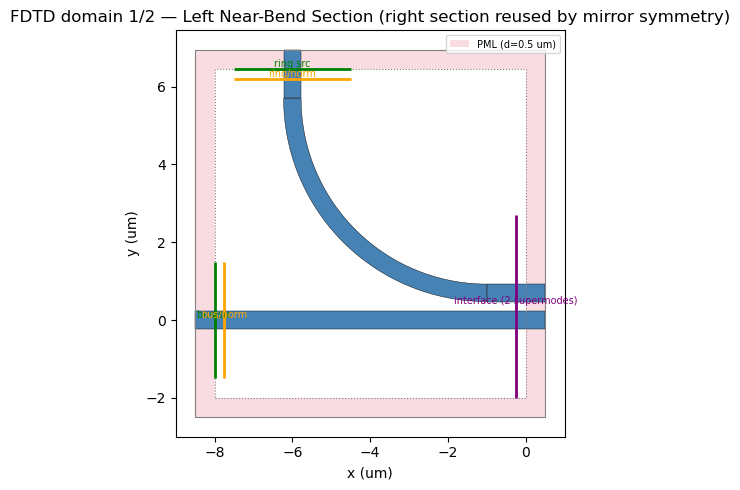

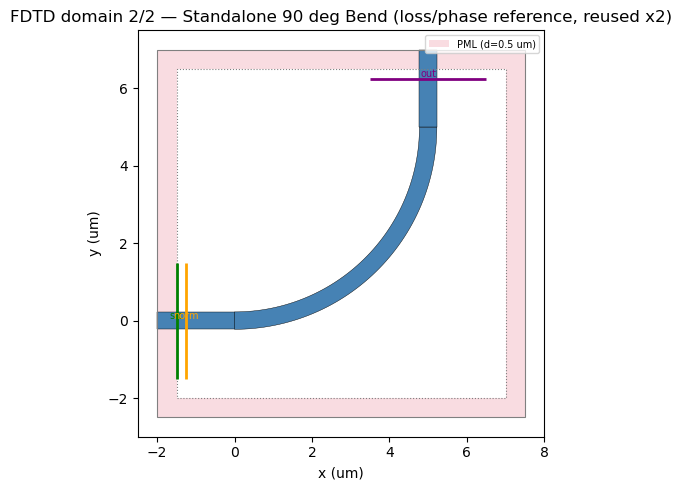

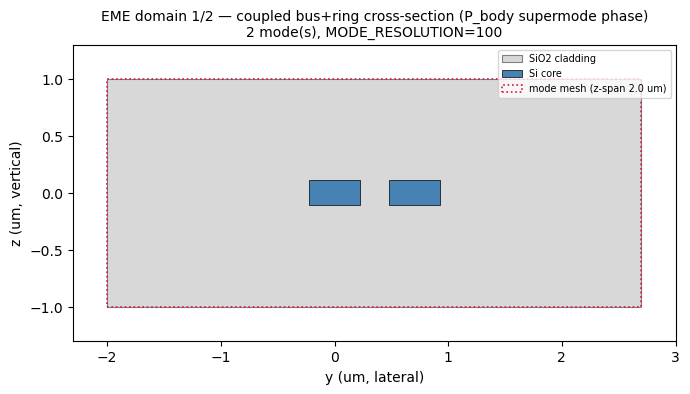

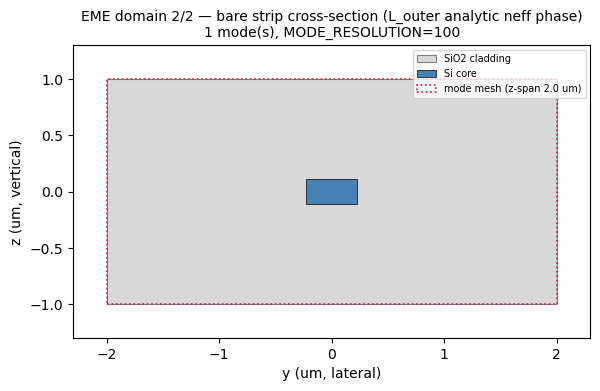

Section previews saved -> /Users/jhiesener/Documents/Research/duty/example_output/ring_resonator/ring_resonator_hybrid_cascaded/sections/ (fdtd_left_section, fdtd_standalone_bend, eme_body_cross_section, eme_strip_cross_section)


In [13]:
# ---------------------------------------------------------------------------
# 10. Geometry preview plots
# ---------------------------------------------------------------------------
def plot_cell(polys, cell_size, geometry_center, monitors, path, title):
    fig, ax = plt.subplots(figsize=(7, 5))
    cx, cy = geometry_center
    sx, sy = cell_size

    outer = mpatches.Rectangle((cx - sx / 2, cy - sy / 2), sx, sy)
    inner = mpatches.Rectangle((cx - sx / 2 + DPML, cy - sy / 2 + DPML), sx - 2 * DPML, sy - 2 * DPML)
    pml_path = mpath.Path.make_compound_path(
        mpath.Path(outer.get_verts()[::-1]), mpath.Path(inner.get_verts())
    )
    ax.add_patch(mpatches.PathPatch(pml_path, facecolor="crimson", alpha=0.15, edgecolor="none",
                                     zorder=0, label="PML"))

    for poly in polys:
        ax.add_patch(mpatches.Polygon(poly, closed=True, facecolor="steelblue", edgecolor="k", lw=0.3))
    ax.add_patch(mpatches.Rectangle((cx - sx / 2, cy - sy / 2), sx, sy, fill=False, edgecolor="gray", lw=0.8))
    ax.add_patch(mpatches.Rectangle((cx - sx / 2 + DPML, cy - sy / 2 + DPML), sx - 2 * DPML, sy - 2 * DPML,
                                     fill=False, edgecolor="gray", linestyle=":", lw=0.8))
    for (kind, x0, y0, x1, y1, label, color) in monitors:
        ax.plot([x0, x1], [y0, y1], color=color, lw=2.0, solid_capstyle="butt")
        ax.annotate(label, (0.5 * (x0 + x1), 0.5 * (y0 + y1)), fontsize=7, color=color,
                    ha="center", va="bottom")
    ax.set_xlim(cx - sx / 2 - 0.5, cx + sx / 2 + 0.5)
    ax.set_ylim(cy - sy / 2 - 0.5, cy + sy / 2 + 0.5)
    ax.set_aspect("equal")
    ax.set_xlabel("x (um)")
    ax.set_ylabel("y (um)")
    ax.set_title(title)
    ax.legend(handles=[mpatches.Patch(facecolor="crimson", alpha=0.15, label=f"PML (d={DPML} um)")],
              loc="upper right", fontsize=7)
    plt.tight_layout()
    fig.savefig(path, dpi=600)
    plt.show()
    plt.close("all")

def _mon_seg(width, x=None, y=None, xc=None, yc=None):
    if x is not None:
        return (x, yc - width / 2, x, yc + width / 2)
    return (xc - width / 2, y, xc + width / 2, y)

plot_cell(
    build_left_polys(), (LEFT_SX, LEFT_SY), (LEFT_X_CENTER, LEFT_Y_CENTER),
    [
        ("src", *_mon_seg(PORT_APERTURE, x=-INNER_X_HALF, yc=0.0), "bus src", "green"),
        ("mon", *_mon_seg(PORT_APERTURE, x=-INNER_X_HALF + MONITOR_MARGIN, yc=0.0), "bus/norm", "orange"),
        ("src", *_mon_seg(PORT_APERTURE, xc=-STUB_X, y=LEFT_STUB_TOP), "ring src", "green"),
        ("mon", *_mon_seg(PORT_APERTURE, xc=-STUB_X, y=LEFT_RING_Y), "ring/norm", "orange"),
        ("mon", *_mon_seg(IFACE_WIDTH, x=IFACE_PLANE_L, yc=IFACE_Y_CENTER), "interface (2 supermodes)", "purple"),
    ],
    os.path.join(sections_dir, "fdtd_left_section.png"),
    "FDTD domain 1/2 — Left Near-Bend Section (right section reused by mirror symmetry)",
)
plot_cell(
    build_bend_polys(), (BEND_SX, BEND_SY), (BEND_X_CENTER, BEND_Y_CENTER),
    [
        ("src", *_mon_seg(PORT_APERTURE, x=-STUB_LEN + SOURCE_MARGIN, yc=0.0), "src", "green"),
        ("mon", *_mon_seg(PORT_APERTURE, x=-STUB_LEN + MONITOR_MARGIN, yc=0.0), "norm", "orange"),
        ("mon", *_mon_seg(PORT_APERTURE, xc=R, y=R + STUB_LEN - MONITOR_MARGIN), "out", "purple"),
    ],
    os.path.join(sections_dir, "fdtd_standalone_bend.png"),
    "FDTD domain 2/2 — Standalone 90 deg Bend (loss/phase reference, reused x2)",
)

def plot_cross_section(wg_polys, ox_polys, path, title, n_modes, mesh_height):
    """Transverse (y-z) mode-solve cross-section preview.

    The EME/mode-solve half has no x-y layout to show — what it actually solves
    is a cross-section, so that is what gets drawn: lateral y from the polygons
    the fingerprint records, vertical z from MATERIAL_STACK's own extrusion
    rules (Si core over [-h/2, h/2], oxide out to +-sz/2 -- see
    MaterialStack.extrusion_rules_at()). Nothing here re-derives a z bound.
    """
    h, sz = MATERIAL_STACK.wg_height, MATERIAL_STACK.sz
    fig, ax = plt.subplots(figsize=(7, 4))

    ys = [y for poly in ox_polys for _, y in poly]
    y_lo, y_hi = min(ys), max(ys)
    ax.add_patch(mpatches.Rectangle((y_lo, -sz / 2), y_hi - y_lo, sz,
                                    facecolor="#d8d8d8", edgecolor="gray",
                                    lw=0.8, zorder=0, label="SiO2 cladding"))
    lbl = "Si core"
    for poly in wg_polys:
        pys = [y for _, y in poly]
        ax.add_patch(mpatches.Rectangle((min(pys), -h / 2), max(pys) - min(pys), h,
                                        facecolor="steelblue", edgecolor="k",
                                        lw=0.5, zorder=2, label=lbl))
        lbl = None
    # Mode-solve mesh z-span, which is a separate knob from the stack's sz.
    ax.add_patch(mpatches.Rectangle((y_lo, -mesh_height / 2), y_hi - y_lo, mesh_height,
                                    fill=False, edgecolor="crimson", ls=":", lw=1.2,
                                    zorder=3, label=f"mode mesh (z-span {mesh_height:.1f} um)"))
    ax.set_xlim(y_lo - 0.3, y_hi + 0.3)
    ax.set_ylim(-sz / 2 - 0.3, sz / 2 + 0.3)
    ax.set_aspect("equal")
    ax.set_xlabel("y (um, lateral)")
    ax.set_ylabel("z (um, vertical)")
    ax.set_title(f"{title}\n{n_modes} mode(s), MODE_RESOLUTION={MODE_RESOLUTION:g}", fontsize=10)
    ax.legend(loc="upper right", fontsize=7)
    plt.tight_layout()
    fig.savefig(path, dpi=600)
    plt.show()
    plt.close("all")

_body_wg, _body_ox = build_body_cross_section()
plot_cross_section(
    _body_wg, _body_ox, os.path.join(sections_dir, "eme_body_cross_section.png"),
    "EME domain 1/2 — coupled bus+ring cross-section (P_body supermode phase)",
    n_modes=N_MODES, mesh_height=MESH_HEIGHT,
)
_strip_wg, _strip_ox = build_strip_cross_section()
plot_cross_section(
    _strip_wg, _strip_ox, os.path.join(sections_dir, "eme_strip_cross_section.png"),
    "EME domain 2/2 — bare strip cross-section (L_outer analytic neff phase)",
    n_modes=1, mesh_height=MESH_HEIGHT,
)
print(f"Section previews saved -> {sections_dir}/ "
      f"(fdtd_left_section, fdtd_standalone_bend, eme_body_cross_section, eme_strip_cross_section)")

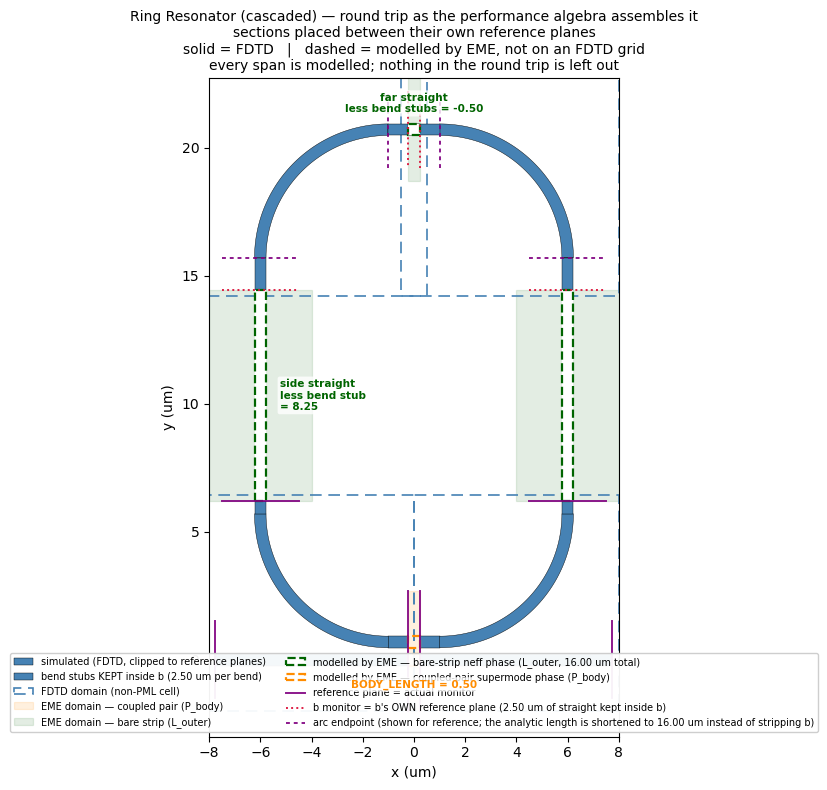

Assembly diagram saved -> /Users/jhiesener/Documents/Research/duty/example_output/ring_resonator/ring_resonator_hybrid_cascaded/geometry_assembly.png

Round-trip ledger — assigned length vs physical span between reference planes
  span                                        modelled by                             assigned  physical  mismatch
  ----------------------------------------------------------------------------------------------------------------
  left section: ring port -> interface        M_left (FDTD)                           measured    9.1040         —
  body: interface -> interface                P_body (supermode phase)                  0.5000    0.5000   +0.0000
  right section: interface -> ring port       M_left.T (reuse)                        measured    9.1040         —
  right side straight (less bend stubs)       L_outer (analytic neff)                   8.2500    8.2500   +0.0000
  far-right bend arc + its 2x1.25 stubs       b as measured (DC-style: analytic l

0.0

In [14]:
# ---------------------------------------------------------------------------
# 10b. Whole-device assembly diagram + round-trip ledger.
#
#      This device is never drawn anywhere as one geometry: the left section is
#      FDTD, the right section is only ever M_left.T, the body is a supermode
#      phase, and L_SIDE/L_FAR are not drawn AT ALL (pure analytic neff phase).
#      So there is no single polygon set to plot and no cut-based section view
#      like the MMI/DirectionalCoupler have -- section_gds(x0,x1)'s x-in/y-out
#      contract cannot express a y-normal ring port or a closed loop anyway
#      (see beef/geometry/ring_coupler.py's class docstring).
#
#      What CAN be drawn is the round trip as the performance algebra actually
#      assembles it: each simulated section placed between the very reference
#      planes its coefficients are normalized to, and each analytic-only span
#      drawn dashed across the gap it is assumed to fill. That makes the
#      diagram a CHECK on the phase bookkeeping rather than a picture of
#      intent: if a span the algebra assigns length L sits in a physical gap of
#      length != L, the ledger below says so in micrometres.
#
#      Everything here CONSUMES build_left_polys()/build_bend_polys() and the
#      module constants. Nothing re-derives a coordinate -- a diagram that
#      computes its own geometry can agree with a wrong model, which is worse
#      than no diagram (cf. the gap-3 lever arm, hardcoded and unchecked).
# ---------------------------------------------------------------------------
ARC_LEN = np.pi * R / 2.0          # quarter-circle centerline path length

BUS_PLANE_L = -INNER_X_HALF + MONITOR_MARGIN
BUS_PLANE_R = -BUS_PLANE_L
Y_ARC_LO = Y_RING + R + L_SIDE      # far-bend arc start (top of each side straight)
Y_FAR = Y_ARC_LO + R                # far straight's y

def _xf(polys, fn):
    """Apply point map `fn` to every vertex of every polygon."""
    return [[fn(x, y) for x, y in poly] for poly in polys]

def _clip_halfplane(poly, keep):
    """Sutherland-Hodgman clip of one polygon to the half-plane keep(x,y) >= 0.

    Used to trim each placed section down to exactly its reference planes, so
    the diagram shows the span each coefficient is normalized over and not the
    section's PML padding (which overlaps its neighbour once placed)."""
    out = []
    for i in range(len(poly)):
        cx, cy = poly[i]
        px, py = poly[i - 1]
        dc, dp = keep(cx, cy), keep(px, py)
        if dc >= 0:
            if dp < 0:
                t = dp / (dp - dc)
                out.append((px + t * (cx - px), py + t * (cy - py)))
            out.append((cx, cy))
        elif dp >= 0:
            t = dp / (dp - dc)
            out.append((px + t * (cx - px), py + t * (cy - py)))
    return out

def _clip_all(polys, keeps):
    """Clip every polygon by every half-plane in `keeps`, dropping empties."""
    out = []
    for poly in polys:
        p = list(poly)
        for keep in keeps:
            p = _clip_halfplane(p, keep)
            if len(p) < 3:
                p = []
                break
        if p:
            out.append(p)
    return out

# Placement maps. Each sends the ORIGINAL builder frame into the ring frame;
# entry/exit points are asserted below rather than trusted.
#   left section  : identity (it is already drawn in the device frame)
#   right section : x-mirror -- the M_left.T reuse, made visible
#   far-left bend : reflect across y=x (in +y, out +x), then translate
#   far-right bend: reflect y (in +x, out -y), then translate
_XF_RIGHT_SECTION = lambda x, y: (-x, y)
_XF_BEND_FAR_L = lambda x, y: (y - STUB_X, x + Y_ARC_LO)
_XF_BEND_FAR_R = lambda x, y: (x + L_C / 2, Y_FAR - y)

# The standalone bend's own frame: arc runs (0,0) -> (R,R) (see build_bend_polys).
assert np.allclose(_XF_BEND_FAR_L(0.0, 0.0), (-STUB_X, Y_ARC_LO))
assert np.allclose(_XF_BEND_FAR_L(R, R), (-L_C / 2, Y_FAR))
assert np.allclose(_XF_BEND_FAR_R(0.0, 0.0), (L_C / 2, Y_FAR))
assert np.allclose(_XF_BEND_FAR_R(R, R), (STUB_X, Y_ARC_LO))

def device_assembly_ledger():
    """Round-trip ledger: for each contribution to the ring's optical path,
    the length the performance algebra assigns vs the physical span between
    the reference planes that bound it.

    Returns a list of dicts with keys: span, modelled_by, assigned (None when
    a span is measured by FDTD and so carries no length assumption), physical,
    mismatch.

    A non-zero `mismatch` is a phase-bookkeeping defect: resonance position is
    set by round-trip phase, so an un-modelled dL contributes
    2*pi*neff*dL/lambda of unaccounted phase.
    """
    rows = [
        # Measured spans: FDTD normalizes between two planes, so no length is
        # assumed and no mismatch is possible by construction.
        dict(span="left section: ring port -> interface", modelled_by="M_left (FDTD)",
             assigned=None,
             physical=S_MON + ARC_LEN + (IFACE_PLANE_L - (-L_C / 2))),
        dict(span="body: interface -> interface", modelled_by="P_body (supermode phase)",
             assigned=BODY_LENGTH,
             physical=IFACE_PLANE_R - IFACE_PLANE_L),
        # Exact x-mirror of the left section (that is what makes M_left.T a
        # valid reuse), so its physical span is identical -- written as the
        # same expression rather than a copied number.
        dict(span="right section: interface -> ring port", modelled_by="M_left.T (reuse)",
             assigned=None,
             physical=(IFACE_PLANE_L - (-L_C / 2)) + ARC_LEN + S_MON),
        # --- the outer half: where the bend-straight accounting shows up ------
        #
        # THE SPAN BOUNDARIES MOVE WITH THE ACCOUNTING, and the ledger has to
        # follow or it misreports who owns what. Under the phase-strip form the
        # bend rows are the ARC ALONE and the analytic model owns all
        # L_OUTER = 7.00 um of straight. Under the DC-style form (the default
        # since 2026-08-03) b keeps its own 1.25 um on each side of each arc, so
        # each bend row is arc + 2.50 um and the analytic model owns only
        # L_OUTER - BEND_STRAIGHT_TOTAL = 2.00 um:
        #
        #     side straight  1.50 -> 0.25 each   (1.25 eaten by the adjacent bend)
        #     far straight   4.00 -> 1.50        (1.25 eaten at EACH end)
        #     total analytic 7.00 -> 2.00
        #
        # Both add to the same PERIMETER -- the cross-check below proves it --
        # but reporting 7.00 um of analytic straight while the code propagates
        # 2.00 um would describe a model that is not running.
        dict(span=f"right side straight{_BEND_SPAN_NOTE}",
             modelled_by="L_outer (analytic neff)",
             assigned=(L_SIDE - S_MON) - _BEND_EAT,
             physical=(Y_ARC_LO - LEFT_RING_Y) - _BEND_EAT),
        # Label AND span reflect which accounting is active (the two are
        # numerically identical; see the P assembly). Saying "planes stripped"
        # under the DC-style form would describe code that does not run.
        dict(span=f"far-right bend{_BEND_ARC_NOTE}", modelled_by=_BEND_LABEL,
             assigned=ARC_LEN + 2 * _BEND_EAT, physical=ARC_LEN + 2 * _BEND_EAT),
        dict(span=f"far straight{_BEND_SPAN_NOTE}",
             modelled_by="L_outer (analytic neff)",
             assigned=L_FAR - 2 * _BEND_EAT,
             physical=((L_C / 2) - (-L_C / 2)) - 2 * _BEND_EAT),
        dict(span=f"far-left bend{_BEND_ARC_NOTE}", modelled_by=_BEND_LABEL,
             assigned=ARC_LEN + 2 * _BEND_EAT, physical=ARC_LEN + 2 * _BEND_EAT),
        dict(span=f"left side straight{_BEND_SPAN_NOTE}",
             modelled_by="L_outer (analytic neff)",
             assigned=(L_SIDE - S_MON) - _BEND_EAT,
             physical=(Y_ARC_LO - LEFT_RING_Y) - _BEND_EAT),
    ]
    for r in rows:
        r["mismatch"] = None if r["assigned"] is None else r["assigned"] - r["physical"]
    return rows

def print_assembly_ledger(rows=None):
    """Print the ledger and the round-trip totals. Returns total mismatch (um)."""
    rows = device_assembly_ledger() if rows is None else rows
    print("\nRound-trip ledger — assigned length vs physical span between reference planes")
    print(f"  {'span':44s}{'modelled by':38s}{'assigned':>10s}{'physical':>10s}{'mismatch':>10s}")
    print("  " + "-" * 112)
    total_mismatch = 0.0
    for r in rows:
        a = "measured" if r["assigned"] is None else f"{r['assigned']:.4f}"
        m = "     —" if r["mismatch"] is None else f"{r['mismatch']:+.4f}"
        if r["mismatch"] is not None:
            total_mismatch += r["mismatch"]
        flag = "  <-- MISMATCH" if r["mismatch"] not in (None,) and abs(r["mismatch"]) > 1e-9 else ""
        print(f"  {r['span']:44s}{r['modelled_by']:38s}{a:>10s}{r['physical']:10.4f}{m:>10s}{flag}")
    print(f"\n  Bend straight-stub budget: b^2 carries {BEND_STRAIGHT_TOTAL:.4f} um of straight "
          f"(phase stripped, magnitude NOT)")
    print(f"    vs L_OUTER = {L_OUTER:.4f} um of physical straight  ->  DC-style equivalent "
          f"analytic length {BEND_STRAIGHT_HEADROOM:.4f} um")
    print(f"    HEADROOM {BEND_STRAIGHT_HEADROOM:.4f} um before the strip becomes MANDATORY "
          f"(guarded at import; the DC's own assert is `body_lengths[0] >= 0`)")
    physical_total = sum(r["physical"] for r in rows)
    print("  " + "-" * 112)
    print(f"  {'physical round trip (sum of spans)':44s}{'':38s}{'':>10s}{physical_total:10.4f}")
    print(f"  {'PERIMETER constant':44s}{'':38s}{'':>10s}{PERIMETER:10.4f}"
          f"   (delta {physical_total - PERIMETER:+.2e})")
    if abs(total_mismatch) > 1e-9:
        print(f"\n  ** TOTAL UNMODELLED PATH: {total_mismatch:+.4f} um **")
        print(f"     At neff~{2.34:.2f}, lambda=1.55 um that is "
              f"{2 * np.pi * 2.34 * abs(total_mismatch) / 1.55:.3f} rad "
              f"({2 * np.pi * 2.34 * abs(total_mismatch) / 1.55 / (2 * np.pi):.3f} of a full FSR) "
              f"of unaccounted round-trip phase.")
    else:
        print("\n  Every assigned length matches its physical span. Bookkeeping closes.")
    return total_mismatch

def plot_device_assembly(path):
    """Draw the round trip as the algebra assembles it.

    Solid   = simulated, clipped to the reference planes its coefficients are
              normalized between.
    Hatched = drawn in an FDTD domain but STRIPPED by a reference-plane
              correction (the standalone bend's approach/exit stubs, removed
              from b so b represents the arc alone).
    Dashed  = never drawn or simulated at all; carried only as analytic neff
              phase in L_outer, or as P_body's supermode phase.
    """
    fig, ax = plt.subplots(figsize=(9, 8))

    left = _clip_all(build_left_polys(), [
        lambda x, y: IFACE_PLANE_L - x,      # stop at the supermode monitor
        lambda x, y: x - BUS_PLANE_L,        # stop at the bus normalization plane
        lambda x, y: LEFT_RING_Y - y,        # stop at the ring port plane
    ])
    right = _xf(left, _XF_RIGHT_SECTION)

    bend_raw = build_bend_polys()
    arc_keeps = [lambda x, y: x, lambda x, y: R - y]     # the arc alone: x>=0, y<=R
    bend_arc = _clip_all(bend_raw, arc_keeps)
    # The bend's straight stubs, CLIPPED TO b's OWN REFERENCE PLANES.
    #
    # build_bend_polys() runs each stub STUB_LEN + DPML = 2.00 um out from the
    # arc so it can pass through the PML, but b is normalized at
    # BEND_D_IN/OUT = 1.25 um. Only that 1.25 um is part of the coefficient;
    # the remaining 0.75 um is PML scaffolding that no reference plane bounds.
    #
    # Clipping matters now in a way it did not before. Under the phase-strip
    # form these were drawn as faint hatch, so over-drawing them merely looked
    # busy. Under the DC-style form they are drawn SOLID (they are kept inside
    # b), and an unclipped 2.00 um stub paints straight over the 0.25 um side
    # and 1.50 um far analytic spans -- making the EME regions invisible and
    # the ring look fully simulated. The figure then contradicts both the
    # ledger and the code while every number in it is correct.
    bend_strip = (_clip_all(bend_raw, [lambda x, y: -x,
                                       lambda x, y: x + BEND_D_IN])
                  + _clip_all(bend_raw, [lambda x, y: y - R,
                                         lambda x, y: R + BEND_D_OUT - y]))

    for polys, label in ((left, "simulated (FDTD, clipped to reference planes)"),
                         (right, None)):
        for poly in polys:
            ax.add_patch(mpatches.Polygon(poly, closed=True, facecolor="steelblue",
                                          edgecolor="k", lw=0.3, zorder=3,
                                          label=label))
            label = None
    # The stripped stubs land ALONG the analytic spans once placed (the bend's
    # output stub runs down the far straight, its input stub down the side
    # straight) — that overlap is the point: it is FDTD domain the corrected b
    # deliberately does not represent. Kept faint and behind the dashed spans.
    # Under the PHASE-STRIP form these stubs are removed from b, so they are
    # hatched: FDTD domain the corrected coefficient deliberately does not
    # represent. Under the DC-STYLE form they are KEPT inside b -- b is never
    # touched -- so they are simulated like any other FDTD span and drawn
    # solid. Drawing them hatched there would claim a correction that is not
    # applied, which is exactly the kind of figure/code drift the ledger's
    # PERIMETER row exists to catch on the numeric side.
    _stub_kept = BEND_STRAIGHT_HEADROOM >= 0
    lbl = (f"bend stubs KEPT inside b ({BEND_D_IN + BEND_D_OUT:.2f} um per bend)"
           if _stub_kept else
           "FDTD domain stripped from b (reference-plane correction)")
    for xf in (_XF_BEND_FAR_L, _XF_BEND_FAR_R):
        for poly in _xf(bend_arc, xf):
            ax.add_patch(mpatches.Polygon(poly, closed=True, facecolor="steelblue",
                                          edgecolor="k", lw=0.3, zorder=3))
        for poly in _xf(bend_strip, xf):
            if _stub_kept:
                ax.add_patch(mpatches.Polygon(poly, closed=True, facecolor="steelblue",
                                              edgecolor="k", lw=0.3, zorder=3,
                                              label=lbl))
            else:
                ax.add_patch(mpatches.Polygon(poly, closed=True, facecolor="none",
                                              edgecolor="crimson", lw=0.4, hatch="///",
                                              alpha=0.35, zorder=2, label=lbl))
            lbl = None

    # Analytic-only spans, dashed along the waveguide centerline.
    # ---- simulation DOMAINS, drawn behind everything ----------------------
    # FDTD: each section's own non-PML cell, placed by the same transform that
    # places its polygons. The bend's box lands rotated, which is the point --
    # it is solved in its own frame and reused twice.
    lbl_f = "FDTD domain (non-PML cell)"
    fdtd_boxes = [
        [(LEFT_X_MIN + DPML, LEFT_Y_MIN + DPML), (LEFT_X_MAX - DPML, LEFT_Y_MIN + DPML),
         (LEFT_X_MAX - DPML, LEFT_Y_MAX - DPML), (LEFT_X_MIN + DPML, LEFT_Y_MAX - DPML)],
    ]
    fdtd_boxes.append(_xf([fdtd_boxes[0]], _XF_RIGHT_SECTION)[0])
    bend_box = [(BEND_X_MIN + DPML, BEND_Y_MIN + DPML), (BEND_X_MAX - DPML, BEND_Y_MIN + DPML),
                (BEND_X_MAX - DPML, BEND_Y_MAX - DPML), (BEND_X_MIN + DPML, BEND_Y_MAX - DPML)]
    for xf in (_XF_BEND_FAR_L, _XF_BEND_FAR_R):
        fdtd_boxes.append(_xf([bend_box], xf)[0])
    # Outline only, no fill: these cells are large and two of them overlap
    # across the whole coupling region, so filling them washes the figure out
    # and hides what it is meant to show.
    for box in fdtd_boxes:
        ax.add_patch(mpatches.Polygon(box, closed=True, facecolor="none",
                                      edgecolor="steelblue", lw=1.2,
                                      ls=(0, (7, 4)), zorder=1, label=lbl_f))
        lbl_f = None

    # EME / mode-solve: no cell, only a cross-section swept along a span. Two
    # different cross-sections are in play, hence two shades and two previews
    # in sections/.
    ax.add_patch(mpatches.Rectangle(
        (IFACE_PLANE_L, BODY_Y_CENTER - BODY_MESH_WIDTH / 2),
        IFACE_PLANE_R - IFACE_PLANE_L, BODY_MESH_WIDTH,
        facecolor="darkorange", alpha=0.13, edgecolor="darkorange", lw=0.9, zorder=0,
        label="EME domain — coupled pair (P_body)"))
    lbl_e = "EME domain — bare strip (L_outer)"
    # Same shortening as the analytic waveguides below -- the mode-solve span
    # and the guide it models must agree, or the figure claims EME covers
    # ground the algebra never propagates it over.
    _sd_top = LEFT_RING_Y + (Y_ARC_LO - LEFT_RING_Y) - _BEND_EAT
    _fr_half = L_C / 2 - _BEND_EAT
    for (x0, y0, x1, y1) in (
        (-STUB_X - MESH_WIDTH / 2, LEFT_RING_Y, -STUB_X + MESH_WIDTH / 2, _sd_top),
        (STUB_X - MESH_WIDTH / 2, LEFT_RING_Y, STUB_X + MESH_WIDTH / 2, _sd_top),
        (-_fr_half, Y_FAR - MESH_WIDTH / 2, _fr_half, Y_FAR + MESH_WIDTH / 2),
    ):
        ax.add_patch(mpatches.Rectangle((x0, y0), x1 - x0, y1 - y0,
                                        facecolor="darkgreen", alpha=0.11,
                                        edgecolor="darkgreen", lw=0.9, zorder=0,
                                        label=lbl_e))
        lbl_e = None

    # ---- the un-simulated waveguides, drawn as real waveguides ------------
    # Same width as everything else, hollow: the guide is physically there and
    # carries the mode, it is simply propagated analytically rather than solved
    # on a grid. Drawing it as a centreline made the ring look discontinuous.
    # Hollow, not white-filled: a white fill would paint over the hatched
    # scaffolding underneath, which is exactly what the reader needs to see.
    # SPANS SHRINK UNDER THE DC-STYLE ACCOUNTING. Each far bend keeps
    # BEND_D_IN/OUT = 1.25 um of straight inside b, so the analytic model owns
    # only what is left: the BOTTOM 0.25 um of each side straight (the top 1.25
    # belongs to the adjacent bend's approach stub) and the MIDDLE 1.50 um of
    # the far straight (1.25 eaten at each end). Under the phase-strip form
    # _BEND_EAT is 0 and these revert to the full 1.50 / 1.50 / 4.00.
    lbl_a = (f"modelled by EME — bare-strip neff phase "
             f"(L_outer, {L_OUTER - BEND_STRAIGHT_TOTAL:.2f} um total)")
    _side_top = LEFT_RING_Y + (Y_ARC_LO - LEFT_RING_Y) - _BEND_EAT
    _far_half = L_C / 2 - _BEND_EAT
    analytic_wg = [
        rect_poly(-STUB_X - W / 2, LEFT_RING_Y, -STUB_X + W / 2, _side_top),
        rect_poly(STUB_X - W / 2, LEFT_RING_Y, STUB_X + W / 2, _side_top),
        rect_poly(-_far_half, Y_FAR - W / 2, _far_half, Y_FAR + W / 2),
    ]
    # FILLED WHITE under the DC-style form, hollow under the phase-strip form.
    #
    # The old comment said never to fill, because a white fill would paint over
    # the hatched scaffolding the reader needs to see. That reason is gone here:
    # under the DC-style form the bend stubs are clipped to b's reference planes
    # and drawn solid, so there IS no hatch underneath -- and leaving these
    # hollow made the 1.50 um far-straight gap read as continuous blue, because
    # the pale EME wash sits inside it and the dashed outline frames it. The
    # geometry was correct and the figure still looked wrong, which is the same
    # failure as a correct number with a stale label.
    _analytic_fc = "none" if BEND_STRAIGHT_HEADROOM < 0 else "white"
    for poly in analytic_wg:
        ax.add_patch(mpatches.Polygon(poly, closed=True, facecolor=_analytic_fc,
                                      edgecolor="darkgreen", lw=1.6, ls="--",
                                      zorder=5, label=lbl_a))
        lbl_a = None

    # The body: the coupled bus+ring pair. This IS modelled — EME over its 2
    # supermodes — it is simply not on an FDTD grid. Labelled with its length
    # the same way the other EME spans are.
    lbl_b = "modelled by EME — coupled-pair supermode phase (P_body)"
    for yc in (0.0, Y_RING):
        ax.add_patch(mpatches.Polygon(
            rect_poly(IFACE_PLANE_L, yc - W / 2, IFACE_PLANE_R, yc + W / 2),
            closed=True, facecolor="none", edgecolor="darkorange", lw=1.6,
            ls="--", zorder=5, label=lbl_b))
        lbl_b = None

    # Labels must quote the length ACTUALLY propagated analytically, and the
    # span they annotate must be the shortened one. Under the DC-style form
    # that is 0.25 um per side and 1.50 um across the far straight, not the
    # full 1.50 / 4.00 -- those belong to b now. Quoting L_SIDE-S_MON = 1.50
    # over a span drawn 0.25 um long was the figure disagreeing with both the
    # ledger and the code.
    _side_len = (L_SIDE - S_MON) - _BEND_EAT
    _far_len = L_FAR - 2 * _BEND_EAT
    _side_tag = ("L_SIDE-S_MON" if _BEND_EAT == 0 else "side straight\nless bend stub")
    _far_tag = ("L_FAR" if _BEND_EAT == 0 else "far straight\nless bend stubs")
    for (x0, y0), (x1, y1), tag, colour, kw in [
        ((-STUB_X, LEFT_RING_Y), (-STUB_X, LEFT_RING_Y + _side_len),
         f"{_side_tag}\n= {_side_len:.2f}", "darkgreen",
         dict(xytext=(14, 0), ha="left", va="center")),
        ((-_far_len / 2, Y_FAR), (_far_len / 2, Y_FAR),
         f"{_far_tag} = {_far_len:.2f}", "darkgreen",
         dict(xytext=(0, 11), ha="center", va="bottom")),
        # Same treatment as the two above, so the body reads as a modelled span
        # like any other. Both numbers shown because they disagree.
        ((IFACE_PLANE_L, 0.0), (IFACE_PLANE_R, 0.0),
         f"BODY_LENGTH = {BODY_LENGTH:.2f}",
         "darkorange", dict(xytext=(0, -14), ha="center", va="top")),
    ]:
        ax.annotate(tag, (0.5 * (x0 + x1), 0.5 * (y0 + y1)), fontsize=7.5,
                    color=colour, fontweight="bold",
                    textcoords="offset points", zorder=7,
                    bbox=dict(boxstyle="round,pad=0.2", fc="white",
                              ec="none", alpha=0.8), **kw)

    # Reference planes — the things the whole diagram is keyed to.
    # Planes where a coefficient is normalized DIRECTLY at a monitor.
    lbl_p = "reference plane = actual monitor"
    planes = [
        (*_mon_seg(IFACE_WIDTH, x=IFACE_PLANE_L, yc=IFACE_Y_CENTER),),
        (*_mon_seg(IFACE_WIDTH, x=IFACE_PLANE_R, yc=IFACE_Y_CENTER),),
        (*_mon_seg(PORT_APERTURE, xc=-STUB_X, y=LEFT_RING_Y),),
        (*_mon_seg(PORT_APERTURE, xc=STUB_X, y=LEFT_RING_Y),),
        (*_mon_seg(PORT_APERTURE, x=BUS_PLANE_L, yc=0.0),),
        (*_mon_seg(PORT_APERTURE, x=BUS_PLANE_R, yc=0.0),),
    ]
    for (x0, y0, x1, y1) in planes:
        ax.plot([x0, x1], [y0, y1], color="purple", lw=1.4, alpha=0.9,
                zorder=5, label=lbl_p)
        lbl_p = None

    # The far bends are the one place where the reference plane is NOT a monitor.
    # b is measured between planes BEND_D_IN before the arc and BEND_D_OUT after
    # it (STUB_LEN - MONITOR_MARGIN = 1.25 um each), then phi_bend_correction
    # strips that straight-guide phase so b_corrected refers to the ARC ENDPOINTS.
    # Drawing only the endpoints implied the monitors sat there; drawing only the
    # monitors would imply b includes 2.5 um of straight it does not. Both are
    # shown, distinguished.
    #
    # This is the ring's dual of the DirectionalCoupler's BODY_STUB bookkeeping:
    # the DC SHORTENS its EME body by 2*BODY_STUB, the ring instead PHASE-STRIPS
    # the extra straight out of b and lets L_outer carry those spans. Different
    # mechanism, same job -- and the ledger's PERIMETER row is what proves
    # neither double-counts (43.4159 either way, delta 0.00e+00).
    bend_mons = [
        _mon_seg(PORT_APERTURE, x=-STUB_LEN + MONITOR_MARGIN, yc=0.0),      # b's norm plane
        _mon_seg(PORT_APERTURE, xc=R, y=R + STUB_LEN - MONITOR_MARGIN),     # b's output plane
    ]
    # Both planes are still drawn under either accounting -- what changes is
    # WHICH one b is referenced to, so the labels follow the active form.
    if BEND_STRAIGHT_HEADROOM < 0:
        lbl_m = (f"actual b monitor (phase-stripped back to the arc, "
                 f"{BEND_D_IN + BEND_D_OUT:.2f} um total)")
        lbl_c = "corrected reference plane (arc endpoint, after phi_bend_correction)"
    else:
        lbl_m = (f"b monitor = b's OWN reference plane ({BEND_D_IN + BEND_D_OUT:.2f} um "
                 f"of straight kept inside b)")
        lbl_c = (f"arc endpoint (shown for reference; the analytic length is shortened "
                 f"to {L_OUTER - BEND_STRAIGHT_TOTAL:.2f} um instead of stripping b)")
    for xf in (_XF_BEND_FAR_L, _XF_BEND_FAR_R):
        for (mx0, my0, mx1, my1) in bend_mons:
            (px0, py0), (px1, py1) = xf(mx0, my0), xf(mx1, my1)
            ax.plot([px0, px1], [py0, py1], color="crimson", lw=1.4, ls=":",
                    alpha=0.95, zorder=5, label=lbl_m)
            lbl_m = None
    for (x0, y0, x1, y1) in (
        (*_mon_seg(PORT_APERTURE, xc=-STUB_X, y=Y_ARC_LO),),
        (*_mon_seg(PORT_APERTURE, xc=STUB_X, y=Y_ARC_LO),),
        (*_mon_seg(PORT_APERTURE, x=-L_C / 2, yc=Y_FAR),),
        (*_mon_seg(PORT_APERTURE, x=L_C / 2, yc=Y_FAR),),
    ):
        ax.plot([x0, x1], [y0, y1], color="purple", lw=1.4, ls=(0, (2, 2)),
                alpha=0.9, zorder=5, label=lbl_c)
        lbl_c = None

    rows = device_assembly_ledger()
    bad = [r for r in rows if r["mismatch"] is not None and abs(r["mismatch"]) > 1e-9]
    for r in bad:
        if r["span"].startswith("body"):
            ax.annotate(
                # NOT "this region is unmodelled" -- it is modelled (EME, 2
                # supermodes). What is missing is 0.5 um of LENGTH inside a
                # modelled region. Worded so the plot cannot be misread.
                f"coupled pair IS modelled (EME, {N_MODES} supermodes),\n"
                f"but P_body propagates only {r['assigned']:.2f} um of the\n"
                f"{r['physical']:.2f} um between its reference planes\n"
                f"-> {abs(r['mismatch']):.2f} um of LENGTH unaccounted for",
                (0.0, Y_RING / 2), xycoords="data",
                xytext=(0.0, Y_RING / 2 + 3.2), textcoords="data",
                fontsize=8.5, color="crimson", ha="center", va="center", zorder=8,
                arrowprops=dict(arrowstyle="->", color="crimson", lw=1.2),
                bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="crimson", alpha=0.95))

    ax.set_aspect("equal")
    ax.set_xlabel("x (um)")
    ax.set_ylabel("y (um)")
    ax.set_title("Ring Resonator (cascaded) — round trip as the performance algebra assembles it\n"
                 "sections placed between their own reference planes\n"
                 "solid = FDTD   |   dashed = modelled by EME, not on an FDTD grid\n"
                 "every span is modelled; nothing in the round trip is left out",
                 fontsize=10)
    ax.legend(loc="lower center", fontsize=7, ncol=2, framealpha=0.95)
    ax.set_xlim(-STUB_X - 2.0, STUB_X + 2.0)
    ax.set_ylim(-Y_BELOW - 1.0, Y_FAR + 2.0)
    plt.tight_layout()
    fig.savefig(path, dpi=600)
    plt.show()
    plt.close("all")

plot_device_assembly(os.path.join(output_dir, "geometry_assembly.png"))
print(f"Assembly diagram saved -> {output_dir}/geometry_assembly.png")
print_assembly_ledger()

In [15]:
# ---------------------------------------------------------------------------
# 11. Run the cascade: 2 left-section FDTD excitations + standalone bend
#     FDTD + coupled-pair supermode solve, combined into t/k1/k2/t_ring.
# ---------------------------------------------------------------------------
wl_fdtd = np.linspace(WL_MIN, WL_MAX, N_WL_FDTD)
wl_solve = np.linspace(WL_MIN, WL_MAX, N_WL_SOLVE)

print("\n[1/4] Left-section FDTD, bus-excited...")
M_left_bus = run_left_fdtd("bus", wl_fdtd, save_dir=save_dir)      # [n_wl, N_MODES]

print("[2/4] Left-section FDTD, ring-excited...")
M_left_ring = run_left_fdtd("ring", wl_fdtd, save_dir=save_dir)    # [n_wl, N_MODES]

M_left = np.stack([M_left_bus, M_left_ring], axis=-1)              # [n_wl, N_MODES, 2] cols=[bus_in, ring_in]
M_right = M_left.transpose(0, 2, 1)                                # [n_wl, 2, N_MODES] — reciprocity reuse, NOT resimulated

print("[3/4] Standalone bend FDTD...")
b_raw = run_bend_fdtd(wl_fdtd, save_dir=save_dir)

print(f"[4/4] Coupled-pair (body) supermode solve at {N_WL_SOLVE} wavelengths...")
body_modes = [solve_body_supermodes(wl, save_dir=save_dir) for wl in wl_solve]
neff_even_solve = np.array([m[0] for m in body_modes])
neff_odd_solve = np.array([m[1] for m in body_modes])
neff_even_fit = np.polyfit(wl_solve, neff_even_solve, deg=2)
neff_odd_fit = np.polyfit(wl_solve, neff_odd_solve, deg=2)
neff_even_resid = neff_even_solve - np.polyval(neff_even_fit, wl_solve)
neff_odd_resid = neff_odd_solve - np.polyval(neff_odd_fit, wl_solve)
print(f"  supermode neff fit residual (max abs): even={np.max(np.abs(neff_even_resid)):.2e}, "
      f"odd={np.max(np.abs(neff_odd_resid)):.2e}")

phi_even = 2 * np.pi * np.polyval(neff_even_fit, wl_fdtd) / wl_fdtd * BODY_LENGTH
phi_odd = 2 * np.pi * np.polyval(neff_odd_fit, wl_fdtd) / wl_fdtd * BODY_LENGTH

P_body = np.zeros((N_WL_FDTD, N_MODES, N_MODES), dtype=complex)
P_body[:, 0, 0] = np.exp(1j * phi_even)
P_body[:, 1, 1] = np.exp(1j * phi_odd)

# [bus_out,ring_out] <- 2 supermodes <- [bus_in,ring_in], per wavelength:
_tmp = np.einsum("wij,wjk->wik", P_body, M_left)         # [n_wl, N_MODES, 2]
S_coupler = np.einsum("wij,wjk->wik", M_right, _tmp)     # [n_wl, 2, 2] == M_left.T @ P_body @ M_left, per wl

t = S_coupler[:, 0, 0]        # bus_out  <- bus_in
k1 = S_coupler[:, 1, 0]       # ring_out <- bus_in
k2 = S_coupler[:, 0, 1]       # bus_out  <- ring_in
t_ring = S_coupler[:, 1, 1]   # ring_out <- ring_in

mid = N_WL_FDTD // 2
conserve_a = np.abs(t[mid]) ** 2 + np.abs(k1[mid]) ** 2
conserve_b = np.abs(t_ring[mid]) ** 2 + np.abs(k2[mid]) ** 2
k_mismatch = np.max(np.abs(k1 - k2))
print(f"\nPower-conservation check @ mid-lambda (should be <~1, lossy/leaky by design — "
      f"only 2 of several outgoing ports captured here, same as the monolithic version):")
print(f"  bus-excited path : |t|^2+|k1|^2 = {conserve_a:.4f}")
print(f"  ring-excited path: |t_ring|^2+|k2|^2 = {conserve_b:.4f}")
# ⚠ THIS NUMBER IS A TAUTOLOGY, NOT A MEASUREMENT — corrected 2026-08-03.
# This line used to call it "a stronger guarantee than the monolithic version's
# independently-normalized |k1|~=|k2|". That is backwards. S_coupler =
# M_left.T @ P_body @ M_left makes k1 and k2 THE SAME MATRIX ELEMENT read from
# either side, so machine epsilon here is arithmetic, not physics: the route
# ENFORCES reciprocity rather than verifying it, and the check cannot fail no
# matter what the FDTD returns. An identity is the weakest possible evidence,
# not the strongest. It was briefly recorded as part of this example's
# validation basis on the strength of that wording; the entry is withdrawn.
#
# The real, independent coefficient-level test is the power-conservation pair
# printed above: nothing in the network algebra forces an FDTD-measured M_left
# to conserve power. Measured post-M1 in 3-D (job 11658568):
# |t|^2+|k1|^2 = 0.999640 .. 0.999926, deviation 3.6e-04.
print(f"  reciprocity check: max|k1-k2| = {k_mismatch:.2e} — EXPECTED at machine "
      f"precision and NOT evidence: S_coupler=M_left.T@P_body@M_left makes k1 and k2 "
      f"the same matrix element, so this is an identity, not a measurement. Use the "
      f"power-conservation lines above as the independent check. (The monolithic "
      f"route normalizes the two independently, so there the comparison is real — "
      f"and there it FAILS, at 1.3e-04 with 0.0068*pi of arg drift.)")


[1/4] Left-section FDTD, bus-excited...
  [cache] run_left_fdtd('bus') hit -> /Users/jhiesener/Documents/Research/duty/example_sim_cache/ring_resonator_hybrid_cascaded_run_left_fdtd_bus_RingResonatorLeftSection_dd89646216df1686
[2/4] Left-section FDTD, ring-excited...
  [cache] run_left_fdtd('ring') hit -> /Users/jhiesener/Documents/Research/duty/example_sim_cache/ring_resonator_hybrid_cascaded_run_left_fdtd_ring_RingResonatorLeftSection_0da5503d6e3bd623
[3/4] Standalone bend FDTD...
  [cache] run_bend_fdtd hit -> /Users/jhiesener/Documents/Research/duty/example_sim_cache/ring_resonator_hybrid_cascaded_run_bend_fdtd_run_bend_fdtd_RingResonatorBend_334803fef5f0fe8b
[4/4] Coupled-pair (body) supermode solve at 13 wavelengths...
  supermode neff fit residual (max abs): even=1.45e-05, odd=7.30e-07

Power-conservation check @ mid-lambda (should be <~1, lossy/leaky by design — only 2 of several outgoing ports captured here, same as the monolithic version):
  bus-excited path : |t|^2+|k1|^2 


Bare-strip mode solve at 13 wavelengths...
  neff fit residual (max abs): 7.29e-06


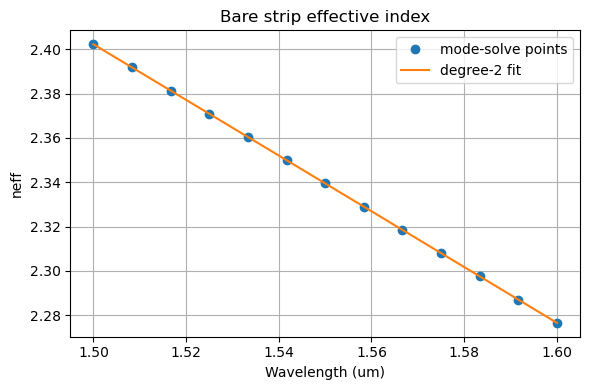

In [16]:
# ---------------------------------------------------------------------------
# 12. Mode solve — bare-strip neff(lambda) for the side/far straights and
#     bend reference-plane correction (unchanged from ring_resonator_hybrid.py).
# ---------------------------------------------------------------------------
print(f"\nBare-strip mode solve at {N_WL_SOLVE} wavelengths...")
neff_solve = np.array([solve_neff(wl, save_dir=save_dir) for wl in wl_solve])
neff_fit = np.polyfit(wl_solve, neff_solve, deg=2)
neff_resid = neff_solve - np.polyval(neff_fit, wl_solve)
print(f"  neff fit residual (max abs): {np.max(np.abs(neff_resid)):.2e}")

fig, ax = plt.subplots(figsize=(6, 4))
wl_fine = np.linspace(WL_MIN, WL_MAX, 200)
ax.plot(wl_solve, neff_solve, "o", label="mode-solve points")
ax.plot(wl_fine, np.polyval(neff_fit, wl_fine), "-", label="degree-2 fit")
ax.set_xlabel("Wavelength (um)")
ax.set_ylabel("neff")
ax.set_title("Bare strip effective index")
ax.legend()
ax.grid(True)
plt.tight_layout()
fig.savefig(os.path.join(output_dir, "neff_lambda.png"), dpi=200)
plt.show()
plt.close("all")

In [17]:
# ---------------------------------------------------------------------------
# 13. Dense-grid assembly (unchanged from ring_resonator_hybrid.py — consumes
#     t/k1/k2/t_ring/b_raw/neff_solve exactly the same way regardless of how
#     they were produced).
# ---------------------------------------------------------------------------
wl_dense = np.linspace(WL_MIN, WL_MAX, N_WL_DENSE)
neff_dense = np.polyval(neff_fit, wl_dense)

t_d = interp_complex(wl_fdtd, t, wl_dense)
k1_d = interp_complex(wl_fdtd, k1, wl_dense)
k2_d = interp_complex(wl_fdtd, k2, wl_dense)
t_ring_d = interp_complex(wl_fdtd, t_ring, wl_dense)
b_d = interp_complex(wl_fdtd, b_raw, wl_dense)

In [18]:
# ---------------------------------------------------------------------------
# Accounting for the straight guide the bend FDTD carries inside b.
#
# TWO EQUIVALENT FORMS, and as of 2026-08-03 the DC-style one is the default:
#
#   phase-strip (old default) : b_corr = b*exp(-i*beta*d) ; analytic length L_OUTER
#   DC-style    (new default) : b untouched               ; analytic length
#                               L_OUTER - BEND_STRAIGHT_TOTAL
#
# Both reduce to b^2 * exp(i*beta*(L_OUTER - BEND_STRAIGHT_TOTAL)), and they do
# so EVEN IF b's internal phase corresponds to a different index than the
# analytic beta -- the strip and the re-add use the same beta and cancel
# exactly. Verified numerically here every run (see the assert below), not just
# remembered: a deliberate n_true = n_analytic + 0.025 test reproduced both to
# 7e-15 in P.
#
# So this switch changes NO NUMBER. It is a robustness change, for two reasons:
#
#  1. `b_corrected` was labelled "the arc alone", and that label is only true if
#     the analytic n_eff really describes the bend's 2.5 um of straight -- the
#     exact assumption currently under investigation for the comb-position
#     phase error. Under the DC form the quantity does not exist and cannot
#     mislead the ledger or the assembly figure.
#  2. n_eff used to enter in TWO places that had to stay in sync (the strip and
#     L_OUTER). They cancel today. The moment a bend-corrected n_eff is used for
#     one and not the other -- which is plausibly part of fixing that phase
#     error -- they would silently stop cancelling. One coupling point is safer
#     than two.
#
# The phase-strip is retained and auto-selected when it is MANDATORY: if the
# bends' own stubs cover more straight than the device physically has between
# its arcs, the DC-style analytic length goes negative and only the strip works.
# Headroom today is 2.0 um (0.5 um in STUB_LEN), so this is not hypothetical.
# ---------------------------------------------------------------------------
USE_PHASE_STRIP = BEND_STRAIGHT_HEADROOM < 0

phi_bend_correction = 2 * np.pi * neff_dense * (BEND_D_IN + BEND_D_OUT) / wl_dense
b_corrected = b_d * np.exp(-1j * phi_bend_correction)   # reporting + the fallback

if USE_PHASE_STRIP:
    b_eff, L_outer = b_corrected, L_OUTER
else:
    b_eff, L_outer = b_d, L_OUTER - BEND_STRAIGHT_TOTAL

phi = 2 * np.pi * neff_dense * L_outer / wl_dense
P = (b_eff ** 2) * np.exp(1j * phi)

# Standing equivalence check. Whenever BOTH forms are legal they must agree, so
# assert it every run rather than relying on the one-off 2026-08-03 measurement.
# This is what stops a future edit to either branch from silently diverging.
if BEND_STRAIGHT_HEADROOM >= 0:
    _P_strip = (b_corrected ** 2) * np.exp(
        1j * 2 * np.pi * neff_dense * L_OUTER / wl_dense)
    _P_dc = (b_d ** 2) * np.exp(
        1j * 2 * np.pi * neff_dense * (L_OUTER - BEND_STRAIGHT_TOTAL) / wl_dense)
    _worst = float(np.max(np.abs(_P_strip - _P_dc)))
    assert _worst < 1e-12, (
        f"the phase-strip and DC-style bend-straight accountings disagree by "
        f"{_worst:.3e} in P. They are algebraically identical, so a nonzero "
        f"difference means one branch has been edited without the other.")
    print(f"[bend-straight] DC-style form (analytic length "
          f"{L_OUTER - BEND_STRAIGHT_TOTAL:.2f} um); equivalence to the "
          f"phase-strip verified to {_worst:.1e} in P")

E_thru = t_d + k1_d * k2_d * P / (1.0 - t_ring_d * P)
T = np.abs(E_thru) ** 2

dips = find_dips(wl_dense, T)
if len(dips) >= 2:
    fsr_meas = np.mean(np.diff([d[0] for d in dips]))
else:
    fsr_meas = np.nan
print(f"\nDense-grid assembly ({N_WL_DENSE} points): {len(dips)} resonance dip(s) found.")
print(f"  Measured mean FSR: {fsr_meas*1000:.3f} nm (predicted: {FSR_GUESS*1000:.2f} nm)")
if dips:
    print(f"  {'lambda (um)':>12}  {'T_min':>8}  {'FWHM (nm)':>10}  {'Q':>10}")
    for wl0, Tmin, fwhm, q in dips[:10]:
        print(f"  {wl0:12.4f}  {Tmin:8.4f}  {fwhm*1000:10.4f}  {q:10.1f}")

wl_c = wl_dense[len(wl_dense) // 2]
idx = np.argmin(np.abs(wl_dense - wl_c))
print(f"\nResults at lambda = {wl_c:.4f} um:")
print(f"  |t|={np.abs(t_d[idx]):.4f}  |k1|={np.abs(k1_d[idx]):.4f}  |k2|={np.abs(k2_d[idx]):.4f}  "
      f"|t_ring|={np.abs(t_ring_d[idx]):.4f}  |b|={np.abs(b_corrected[idx]):.4f}")
print(f"  T_through = {T[idx]:.4f}  IL = {10*np.log10(max(T[idx],1e-20)):.2f} dB")

[bend-straight] DC-style form (analytic length 16.00 um); equivalence to the phase-strip verified to 5.0e-14 in P

Dense-grid assembly (20001 points): 10 resonance dip(s) found.
  Measured mean FSR: 10.028 nm (predicted: 10.08 nm)
   lambda (um)     T_min   FWHM (nm)           Q
        1.5037    0.0672      0.0500     30074.5
        1.5133    0.0950      0.0550     27515.0
        1.5230    0.1073      0.0600     25383.9
        1.5329    0.1328      0.0650     23582.3
        1.5428    0.1590      0.0700     22039.6
        1.5528    0.1893      0.0750     20703.9
        1.5629    0.2218      0.0850     18387.4
        1.5732    0.2548      0.0900     17479.7
        1.5835    0.2917      0.1000     15835.2
        1.5940    0.3323      0.1050     15180.8

Results at lambda = 1.5500 um:
  |t|=0.9851  |k1|=0.1713  |k2|=0.1713  |t_ring|=0.9815  |b|=0.9988
  T_through = 0.9999  IL = -0.00 dB


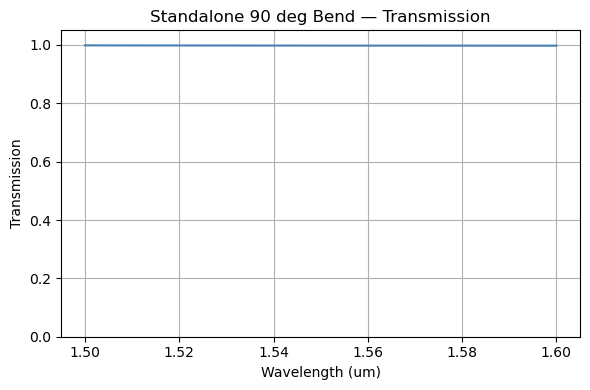

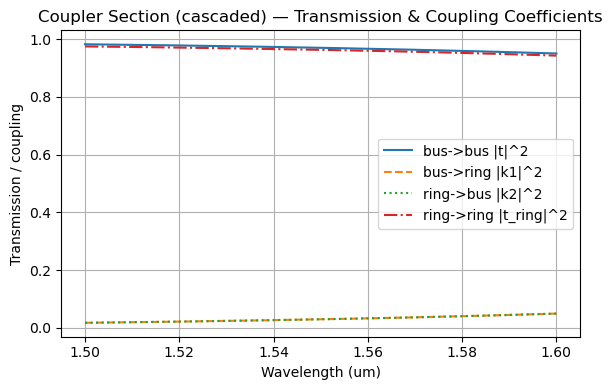

Bend/coupler transmission plots saved -> /Users/jhiesener/Documents/Research/duty/example_output/ring_resonator/ring_resonator_hybrid_cascaded/bend_transmission.png, coupler_transmission.png


In [19]:
# ---------------------------------------------------------------------------
# 14. Independent bend / coupler-region transmission plots (unchanged from
#     ring_resonator_hybrid.py).
# ---------------------------------------------------------------------------
T_bend = np.abs(b_d) ** 2

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(wl_dense, T_bend, color="steelblue")
ax.set_xlabel("Wavelength (um)")
ax.set_ylabel("Transmission")
ax.set_title("Standalone 90 deg Bend — Transmission")
ax.grid(True)
ax.set_ylim(0, 1.05)
plt.tight_layout()
fig.savefig(os.path.join(output_dir, "bend_transmission.png"), dpi=300)
plt.show()
plt.close("all")

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(wl_dense, np.abs(t_d) ** 2, label="bus->bus |t|^2")
ax.plot(wl_dense, np.abs(k1_d) ** 2, linestyle="--", label="bus->ring |k1|^2")
ax.plot(wl_dense, np.abs(k2_d) ** 2, linestyle=":", label="ring->bus |k2|^2")
ax.plot(wl_dense, np.abs(t_ring_d) ** 2, linestyle="-.", label="ring->ring |t_ring|^2")
ax.set_xlabel("Wavelength (um)")
ax.set_ylabel("Transmission / coupling")
ax.set_title("Coupler Section (cascaded) — Transmission & Coupling Coefficients")
ax.legend()
ax.grid(True)
plt.tight_layout()
fig.savefig(os.path.join(output_dir, "coupler_transmission.png"), dpi=300)
plt.show()
plt.close("all")
print(f"Bend/coupler transmission plots saved -> {output_dir}/bend_transmission.png, coupler_transmission.png")


SMatrix saved -> /Users/jhiesener/Documents/Research/duty/example_output/ring_resonator/ring_resonator_hybrid_cascaded/smatrix_hybrid.pkl
Data saved -> /Users/jhiesener/Documents/Research/duty/example_output/ring_resonator/ring_resonator_hybrid_cascaded/ring_data.npz


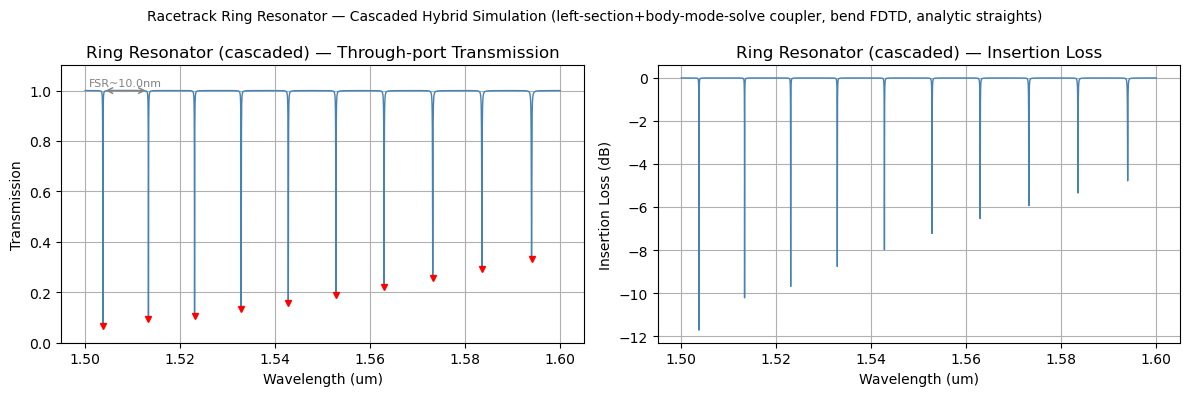

Results plot saved -> /Users/jhiesener/Documents/Research/duty/example_output/ring_resonator/ring_resonator_hybrid_cascaded/hybrid_results.png


In [20]:
# ---------------------------------------------------------------------------
# 15. Save and plot (unchanged from ring_resonator_hybrid.py).
# ---------------------------------------------------------------------------
smat = SMatrix(wavelengths=wl_dense)
smat.set(E_thru, port="through")
smat.check_passive()
smat.save(os.path.join(output_dir, "smatrix_hybrid.pkl"))
print(f"\nSMatrix saved -> {output_dir}/smatrix_hybrid.pkl")

np.savez(
    os.path.join(output_dir, "ring_data.npz"),
    wl_fdtd=wl_fdtd, wl_dense=wl_dense, wl_solve=wl_solve,
    t=t, k1=k1, k2=k2, t_ring=t_ring, b_raw=b_raw,
    neff_solve=neff_solve, neff_dense=neff_dense,
    neff_even_solve=neff_even_solve, neff_odd_solve=neff_odd_solve,
    T=T, dips=np.array([(d[0], d[1], d[2], d[3]) for d in dips]) if dips else np.empty((0, 4)),
    perimeter=PERIMETER, fsr_guess=FSR_GUESS,
)
print(f"Data saved -> {output_dir}/ring_data.npz")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ax = axes[0]
ax.plot(wl_dense, T, color="steelblue", lw=1.0)
for wl0, Tmin, fwhm, q in dips:
    ax.plot(wl0, Tmin, "rv", ms=4)
if len(dips) >= 2:
    ax.annotate("", xy=(dips[1][0], 1.0), xytext=(dips[0][0], 1.0),
                arrowprops=dict(arrowstyle="<->", color="gray"))
    ax.text(0.5 * (dips[0][0] + dips[1][0]), 1.02, f"FSR~{fsr_meas*1000:.1f}nm",
            ha="center", fontsize=8, color="gray")
ax.set_xlabel("Wavelength (um)")
ax.set_ylabel("Transmission")
ax.set_title("Ring Resonator (cascaded) — Through-port Transmission")
ax.grid(True)
ax.set_ylim(0, 1.1)

ax = axes[1]
IL = 10 * np.log10(np.clip(T, 1e-20, None))
ax.plot(wl_dense, IL, color="steelblue", lw=1.0)
ax.set_xlabel("Wavelength (um)")
ax.set_ylabel("Insertion Loss (dB)")
ax.set_title("Ring Resonator (cascaded) — Insertion Loss")
ax.grid(True)

plt.suptitle("Racetrack Ring Resonator — Cascaded Hybrid Simulation (left-section+body-mode-solve coupler, bend FDTD, analytic straights)",
             fontsize=10)
plt.tight_layout()
fig.savefig(os.path.join(output_dir, "hybrid_results.png"), dpi=300)
plt.show()
plt.close("all")
print(f"Results plot saved -> {output_dir}/hybrid_results.png")